# Perbandingan Fungsi Konsensus Tanpa Bobot untuk Data Campuran UMKM Jawa Timur
### Ensemble 3 base (K-Means · K-Prototypes · K-Medoids Gower) × 6 fungsi konsensus · 3 lapis ketahanan · simulasi semi-sintetis

**Pertanyaan penelitian:** fungsi konsensus mana yang paling sesuai untuk data UMKM bertipe campuran, bila semua partisi dasar diperlakukan setara (tanpa pembobotan)?

```
 DATA AWAL (2.000 baris) → pra-pemrosesan (1.368 UMKM, 6 numerik + 3 biner, log1p + Min-Max)      Bagian 1
   ▼
 Jarak Gower + proyeksi MDS 10 dimensi                                                             Bagian 2
 3 base clustering (seed 42) untuk K = 2–10                                                        Bagian 3–4
 6 fungsi konsensus pada ensemble yang sama                                                        Bagian 3–4
   AHC average (EAC) · AHC complete · Spectral pada C · K-Medoids pada 1−C · MCLA · K-Modes pada label
   ▼
 Evaluasi: SC (Gower) · DBI, CHI (MDS) · ANMI · SC Euclid (uji kepekaan) · ukuran klaster          Bagian 4–5
 Protokol K: K tetap = 3 dan 4 (skor komposit + lifetime dendrogram)                               Bagian 5
   ▼
 Lapis 1  ketahanan terhadap inisialisasi acak (30 seed)                                          Bagian 6
 Lapis 2  ketahanan terhadap cara membangkitkan ensemble (33 partisi, 4 skema, 30 seed)            Bagian 7
 Lapis 3  ketahanan terhadap data (subsampel 80% dan derau biner 5%, 30 replikasi)                 Bagian 8
 Uji Friedman–Nemenyi dengan replikasi sebagai blok                                                Bagian 9
   ▼
 Simulasi semi-sintetis: 180 dataset dengan kelompok diketahui (validasi eksternal)               Bagian 10
 Ekspor 180 dataset semi-sintetis (CSV dalam ZIP) + uji ulang                                     Bagian 10B
   ▼
 Workbook Excel hasil                                                                              Bagian 11
```

**Cara memakai (Colab):** jalankan Bagian 0A (Drive) dan 0B (unggah `dataset_umkmjatim_full2000.xlsx`), lalu **Runtime → Run all**. Langkah berat (lapis 1–3 dan simulasi) disimpan sebagai checkpoint di Drive; bila runtime terputus, jalankan ulang dan bagian yang sudah selesai dibaca dari checkpoint. Perkiraan waktu total ±30–45 menit di Colab (2 inti).

# BAGIAN 0A · Persiapan Colab, paket, dan checkpoint
| | |
|---|---|
| **Tujuan** | Memasang paket, menyambungkan Google Drive, menyiapkan folder hasil dan fungsi checkpoint. |
| **Pengaturan** | `RESET_CHECKPOINT = True` untuk menghitung ulang semuanya; `N_JOBS` = jumlah proses paralel (−1 = semua inti). |

In [1]:
import os, sys, time, pickle, hashlib, importlib, subprocess
for _imp, _pip in [("kmodes", "kmodes"), ("gower", "gower"), ("kmedoids", "kmedoids"), ("pymetis", "pymetis"), ("openpyxl", "openpyxl")]:
    try: importlib.import_module(_imp)
    except ImportError:
        print(f"Memasang {_pip} ..."); subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])
import numpy as np, pandas as pd

try:
    from google.colab import drive
    DI_COLAB = True; drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/UMKM_Fungsi_Konsensus"
except ImportError:
    DI_COLAB = False
    BASE_DIR = os.environ.get("UMKM_BASE_DIR", os.path.abspath("UMKM_Fungsi_Konsensus"))
CKPT_DIR = os.path.join(BASE_DIR, "checkpoint_konsensus"); OUT_DIR = os.path.join(BASE_DIR, "hasil_konsensus")
for _p in (BASE_DIR, CKPT_DIR, OUT_DIR): os.makedirs(_p, exist_ok=True)
print("Folder kerja:", BASE_DIR)

PAKAI_CHECKPOINT = True
RESET_CHECKPOINT = False
N_JOBS = -1
if RESET_CHECKPOINT:
    for _f in os.listdir(CKPT_DIR):
        if _f.endswith((".pkl", ".tmp")): os.remove(os.path.join(CKPT_DIR, _f))
    print("⚠ semua checkpoint dihapus")

def buat_sidik(*objs):
    h = hashlib.sha256()
    for o in objs:
        if isinstance(o, (pd.DataFrame, pd.Series)): h.update(pd.util.hash_pandas_object(o, index=True).values.tobytes())
        elif isinstance(o, np.ndarray): h.update(np.ascontiguousarray(o).tobytes())
        else: h.update(repr(o).encode())
    return h.hexdigest()[:16]
def ckpt_muat(nama, sidik):
    p = os.path.join(CKPT_DIR, nama + ".pkl")
    if not PAKAI_CHECKPOINT or not os.path.exists(p): return None
    try:
        with open(p, "rb") as f: paket = pickle.load(f)
    except Exception: return None
    return paket["isi"] if paket.get("sidik") == sidik else None
def ckpt_simpan(nama, isi, sidik):
    if not PAKAI_CHECKPOINT: return
    p = os.path.join(CKPT_DIR, nama + ".pkl"); tmp = p + ".tmp"
    with open(tmp, "wb") as f: pickle.dump({"sidik": sidik, "isi": isi}, f)
    os.replace(tmp, p)
def dengan_checkpoint(nama, sidik, fungsi):
    isi = ckpt_muat(nama, sidik)
    if isi is not None: print(f"ℹ '{nama}' dibaca dari checkpoint"); return isi
    t0 = time.time(); isi = fungsi(); ckpt_simpan(nama, isi, sidik); print(f"✔ '{nama}' selesai ({time.time()-t0:.0f} detik)"); return isi

Folder kerja: UMKM_Fungsi_Konsensus


# BAGIAN 0B · Unggah data
File `dataset_umkmjatim_full2000.xlsx` cukup diunggah sekali; salinannya disimpan di Drive.

In [2]:
RAW_PATH = os.path.join(BASE_DIR, "dataset_umkmjatim_full2000.xlsx")
if DI_COLAB and not os.path.exists(RAW_PATH):
    from google.colab import files
    print("Pilih dataset_umkmjatim_full2000.xlsx")
    for nama, isi in files.upload().items():
        if "dataset_umkmjatim" in nama.lower():
            with open(RAW_PATH, "wb") as f: f.write(isi)
assert os.path.exists(RAW_PATH), f"Letakkan dataset_umkmjatim_full2000.xlsx di {BASE_DIR}"
print("Data awal:", RAW_PATH)

Data awal: UMKM_Fungsi_Konsensus/dataset_umkmjatim_full2000.xlsx


# BAGIAN 0 · Konfigurasi dan pustaka

In [3]:
import warnings; warnings.filterwarnings("ignore")
from itertools import combinations
import gower, kmedoids, pymetis
from joblib import Parallel, delayed
from scipy.stats import friedmanchisquare, rankdata, spearmanr, norm
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans, AgglomerativeClustering, SpectralClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from kmodes.kprototypes import KPrototypes
from kmodes.kmodes import KModes
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42; K_MIN, K_MAX = 2, 10; KS = list(range(K_MIN, K_MAX + 1)); K_UJI = [3, 4]
TAHUN_REFERENSI = 2026; N_REP = 30
NUMERIK = ["LAMA_USAHA", "JUMLAH_TENAGA_KERJA", "OMSET", "BIAYA_PRODUKSI", "GAJI_KARYAWAN", "SERTIFIKASI_JUMLAH"]
BINER = ["PEMASARAN_ONLINE", "KESULITAN_USAHA", "NIB_STATUS"]
LOG1P = ["OMSET", "BIAYA_PRODUKSI", "GAJI_KARYAWAN"]                 # log1p lalu Min-Max; numerik lain Min-Max saja
B3 = ["K-Means", "K-Prototypes", "K-Medoids"]
CONS6 = ["AHC average", "AHC complete", "Spectral (C)", "K-Medoids (1-C)", "MCLA", "K-Modes (label)"]
SINGKAT = {"AHC average": "AHC avg", "AHC complete": "AHC comp", "Spectral (C)": "Spectral C", "K-Medoids (1-C)": "PAM 1−C",
           "MCLA": "MCLA", "K-Modes (label)": "K-Modes label"}
print("Konfigurasi siap | base:", B3, "| fungsi konsensus:", len(CONS6))

Konfigurasi siap | base: ['K-Means', 'K-Prototypes', 'K-Medoids'] | fungsi konsensus: 6


# BAGIAN 1 · Pra-pemrosesan (sama dengan naskah segmentasi)
| | |
|---|---|
| **Proses** | Hapus duplikat → tahun 0 = missing → jumlah sertifikasi → status NIB → '-' pada pemasaran online = missing → imputasi (median/modus) → lama usaha = 2026 − tahun mulai → encoding biner → log1p (omset, biaya produksi, gaji) → Min-Max semua numerik. |
| **Pemeriksaan** | 1.368 UMKM; 29 sel diimputasi; 9 fitur pada rentang 0–1. |

In [4]:
raw = pd.read_excel(RAW_PATH, dtype=object)
for c in raw.columns: raw[c] = raw[c].map(lambda v: v.strip() if isinstance(v, str) else v)
df = raw.drop_duplicates(keep="first").reset_index(drop=True)
d = pd.DataFrame({"ID_BINAAN": df.ID_BINAAN.astype(int), "NAMA_USAHA": df.NAMA_USAHA, "JENIS_LAPANGAN_USAHA": df.JENIS_LAPANGAN_USAHA})
for c in ["TAHUN_MULAI_USAHA", "JUMLAH_TENAGA_KERJA", "OMSET", "BIAYA_PRODUKSI", "GAJI_KARYAWAN"]: d[c] = pd.to_numeric(df[c], errors="coerce")
d.loc[d.TAHUN_MULAI_USAHA == 0, "TAHUN_MULAI_USAHA"] = np.nan
d["SERTIFIKASI_JUMLAH"] = df.SERTIFIKASI.map(lambda t: 0 if str(t).strip() in ("-", "", "nan") else len([x for x in str(t).split(",") if x.strip()])).astype(int)
d["NIB_STATUS"] = df.NIB.map(lambda s: "TIDAK" if (str(s).strip() == "-" or set(str(s).strip()) == {"0"}) else "YA")
d["PEMASARAN_ONLINE"] = df.PEMASARAN_ONLINE.replace("-", np.nan); d["KESULITAN_USAHA"] = df.KESULITAN_USAHA
VAR_AWAL = ["TAHUN_MULAI_USAHA", "JUMLAH_TENAGA_KERJA", "OMSET", "BIAYA_PRODUKSI", "GAJI_KARYAWAN", "SERTIFIKASI_JUMLAH", "PEMASARAN_ONLINE", "KESULITAN_USAHA", "NIB_STATUS"]
cek_missing = pd.DataFrame({"jumlah missing": d[VAR_AWAL].isna().sum(), "% missing": (d[VAR_AWAL].isna().mean() * 100).round(2)})
log_imp = []
for c in VAR_AWAL:
    m = int(d[c].isna().sum())
    if m == 0: continue
    nilai = d[c].median() if pd.api.types.is_numeric_dtype(d[c]) else d[c].mode().iloc[0]
    d[c] = d[c].fillna(nilai); log_imp.append({"variabel": c, "metode": "median" if pd.api.types.is_numeric_dtype(d[c]) else "modus", "nilai imputasi": nilai, "jumlah diimputasi": m})
log_imputasi = pd.DataFrame(log_imp)
d["LAMA_USAHA"] = TAHUN_REFERENSI - d.TAHUN_MULAI_USAHA
for c in BINER: d[c + "_BIN"] = d[c].map({"YA": 1, "TIDAK": 0}).astype(int)
bersih = d[["ID_BINAAN", "NAMA_USAHA", "JENIS_LAPANGAN_USAHA", "TAHUN_MULAI_USAHA"] + NUMERIK + BINER + [c + "_BIN" for c in BINER]].copy()

def normalisasi(tabel_numerik, tabel_biner):
    X = pd.DataFrame(index=tabel_numerik.index)
    for c in NUMERIK:
        s = tabel_numerik[c].astype(float); s = np.log1p(s) if c in LOG1P else s
        rg = s.max() - s.min(); X[c] = (s - s.min()) / rg if rg > 0 else 0.0
    for c in BINER: X[c] = tabel_biner[c].astype(float).values
    return X
X = normalisasi(bersih[NUMERIK], bersih[[c + "_BIN" for c in BINER]].set_axis(BINER, axis=1)); X.index = bersih.ID_BINAAN.values
print(f"Data awal {raw.shape} | duplikat {len(raw) - len(df)} | UMKM unik {len(df)} | sel diimputasi {int(cek_missing['jumlah missing'].sum())}")
print("✔" if X.shape == (1368, 9) and X.min().min() >= 0 and X.max().max() <= 1 else "✘", "1.368 UMKM × 9 fitur pada rentang 0–1")
display(cek_missing.T); display(log_imputasi)

Data awal (2000, 14) | duplikat 632 | UMKM unik 1368 | sel diimputasi 29
✔ 1.368 UMKM × 9 fitur pada rentang 0–1


,TAHUN_MULAI_USAHA,JUMLAH_TENAGA_KERJA,OMSET,BIAYA_PRODUKSI,GAJI_KARYAWAN,SERTIFIKASI_JUMLAH,PEMASARAN_ONLINE,KESULITAN_USAHA,NIB_STATUS
jumlah missing,4.00,0.0,0.0,0.0,0.0,0.0,25.00,0.0,0.0
% missing,0.29,0.0,0.0,0.0,0.0,0.0,1.83,0.0,0.0


,variabel,metode,nilai imputasi,jumlah diimputasi
0,TAHUN_MULAI_USAHA,median,2017.0,4
1,PEMASARAN_ONLINE,modus,YA,25


# BAGIAN 2 · Jarak Gower dan proyeksi MDS
SC dihitung langsung pada jarak Gower; DBI dan CHI pada proyeksi MDS klasik 10 dimensi dari jarak Gower yang sama.

In [5]:
def gower_of(Xd):
    g = Xd.copy()
    for c in BINER: g[c] = np.where(g[c] == 1, "YA", "TIDAK").astype(object)
    Dm = gower.gower_matrix(g, cat_features=[False] * 6 + [True] * 3).astype(float)
    np.fill_diagonal(Dm, 0.0); return (Dm + Dm.T) / 2
def classical_mds(Dm, k=10):
    n = Dm.shape[0]; J = np.eye(n) - np.ones((n, n)) / n
    B = -0.5 * J @ (Dm ** 2) @ J; w, v = np.linalg.eigh(B); i = np.argsort(w)[::-1][:k]
    return v[:, i] * np.sqrt(np.clip(w[i], 0, None)), w
D = gower_of(X); EMB, EIG = classical_mds(D, 10)
pos = np.sort(EIG[EIG > 0])[::-1]
print(f"MDS 10 dimensi mempertahankan {pos[:10].sum() / pos.sum() * 100:.1f}% variansi positif jarak Gower")

MDS 10 dimensi mempertahankan 88.8% variansi positif jarak Gower


# BAGIAN 3 · Base clustering, 6 fungsi konsensus, dan evaluasi
| Fungsi | Masukan | Cara kerja |
|---|---|---|
| AHC average (EAC) | 1 − C | Agglomerative average linkage, dipotong K |
| AHC complete | 1 − C | Agglomerative complete linkage |
| Spectral (C) | C | Spectral clustering dengan C sebagai afinitas |
| K-Medoids (1−C) | 1 − C | PAM |
| MCLA | klaster tiap base | Meta-graf klaster (Jaccard) dipartisi METIS; objek ke meta-klaster berasosiasi terbesar (Strehl & Ghosh, 2002) |
| K-Modes (label) | matriks label n × M | K-Modes pada label partisi dasar |

C = matriks co-association (proporsi partisi dasar yang menempatkan dua UMKM pada klaster yang sama). Semua fungsi tanpa bobot dan memakai ensemble yang sama.

In [6]:
def base3(Xd, Dm, K, seed=RANDOM_STATE):
    km = KMeans(K, n_init=10, random_state=seed).fit(Xd.to_numpy(float)).labels_
    Xp = np.hstack([Xd[NUMERIK].to_numpy(float), np.where(Xd[BINER].to_numpy() == 1, "YA", "TIDAK")]); kp = None
    for init in ("Huang", "Cao", "random"):
        try: kp = KPrototypes(n_clusters=K, init=init, n_init=5, random_state=seed, verbose=0).fit_predict(Xp, categorical=[6, 7, 8]); break
        except ValueError: continue
    kd = np.asarray(kmedoids.pam(Dm, K, random_state=seed).labels)
    return {"K-Means": np.asarray(km).astype(int), "K-Prototypes": np.asarray(kp).astype(int), "K-Medoids": kd.astype(int)}

def coassoc(parts, names):
    n = len(parts[names[0]]); Cm = np.zeros((n, n), np.float32)
    for a in names: Cm += (parts[a][:, None] == parts[a][None, :]).astype(np.float32)
    return Cm / len(names)
def _rapikan(lab): return np.unique(lab, return_inverse=True)[1].astype(int)
def mcla(parts, names, K, seed=0):
    warnings.filterwarnings("ignore", category=DeprecationWarning)      # peringatan API pymetis
    n = len(parts[names[0]]); H = []
    for a in names:
        for k in np.unique(parts[a]): H.append((parts[a] == k).astype(np.float32))
    H = np.array(H); m = len(H); inter = H @ H.T; sz = H.sum(1); W = inter / (sz[:, None] + sz[None, :] - inter); np.fill_diagonal(W, 0)
    xadj, adjncy, ew = [0], [], []
    for i in range(m):
        nb = list(np.nonzero(W[i] > 0)[0]); adjncy += nb; ew += [int(round(W[i, j] * 1000)) or 1 for j in nb]; xadj.append(len(adjncy))
    _, mem = pymetis.part_graph(K, xadj=xadj, adjncy=adjncy, eweights=ew); mem = np.asarray(mem)
    assoc = np.zeros((n, K), np.float32)
    for g in range(K):
        idx = np.where(mem == g)[0]
        if len(idx): assoc[:, g] = H[idx].mean(0)
    rng = np.random.default_rng(seed); mx = assoc.max(1)
    return np.array([rng.choice(np.where(assoc[i] == mx[i])[0]) for i in range(n)])
def konsensus6(parts, names, K, seed=RANDOM_STATE):
    Cm = coassoc(parts, names); Dj = 1 - Cm; np.fill_diagonal(Dj, 0.0); Dj = ((Dj + Dj.T) / 2).astype(float); out = {}
    out["AHC average"] = AgglomerativeClustering(K, metric="precomputed", linkage="average").fit_predict(Dj)
    out["AHC complete"] = AgglomerativeClustering(K, metric="precomputed", linkage="complete").fit_predict(Dj)
    out["Spectral (C)"] = SpectralClustering(K, affinity="precomputed", assign_labels="kmeans", random_state=seed, n_init=10).fit_predict(Cm.astype(float))
    out["K-Medoids (1-C)"] = np.asarray(kmedoids.pam(Dj, K, random_state=seed).labels)
    out["MCLA"] = mcla(parts, names, K, seed)
    L = np.column_stack([parts[a] for a in names]).astype(str); lk = None
    for init in ("Huang", "Cao"):
        try: lk = KModes(n_clusters=K, init=init, n_init=10, random_state=seed, verbose=0).fit_predict(L); break
        except ValueError: continue
    out["K-Modes (label)"] = lk
    return {k: _rapikan(np.asarray(v)) for k, v in out.items()}

def evaluasi(lab, Dm=None, emb=None):
    Dm = D if Dm is None else Dm; emb = EMB if emb is None else emb
    if len(np.unique(lab)) < 2: return {"SC": np.nan, "DBI": np.nan, "CHI": np.nan}
    return {"SC": silhouette_score(Dm, lab, metric="precomputed"), "DBI": davies_bouldin_score(emb, lab), "CHI": calinski_harabasz_score(emb, lab)}
def anmi(lab, parts, names): return float(np.mean([normalized_mutual_info_score(lab, parts[a]) for a in names]))
def eval_lengkap(lab, parts, names):
    e = evaluasi(lab); e["ANMI"] = anmi(lab, parts, names)
    e["SC Euclid"] = silhouette_score(X.to_numpy(float), lab) if len(np.unique(lab)) > 1 else np.nan
    sz = np.bincount(lab); e["klaster aktif"] = int((sz > 0).sum()); e["klaster terkecil (n)"] = int(sz[sz > 0].min()); e["klaster terbesar (n)"] = int(sz.max())
    return e
def peringkat_komposit(t):
    t = t.copy(); t["R_SC"] = t.SC.rank(ascending=False, method="min"); t["R_DBI"] = t.DBI.rank(method="min"); t["R_CHI"] = t.CHI.rank(ascending=False, method="min")
    t["Peringkat_Komposit"] = t.R_SC + t.R_DBI + t.R_CHI
    return t.sort_values(["Peringkat_Komposit", "SC"], ascending=[True, False]).reset_index(drop=True)
print("✔ fungsi base, konsensus, dan evaluasi siap")

✔ fungsi base, konsensus, dan evaluasi siap


# BAGIAN 4 · Hasil utama pada data asli (K = 2–10)

In [7]:
def _utama():
    hasil = {}
    for K in KS:
        P = base3(X, D, K); out = konsensus6(P, B3, K); hasil[K] = dict(P=P, out=out)
    return hasil
MAIN = dengan_checkpoint("utama_3base_6fungsi", buat_sidik("utama", X, KS, RANDOM_STATE, CONS6), _utama)
rows = []
for K in KS:
    for c in CONS6: rows.append(dict(K=K, Jenis="Konsensus", Metode=c, **eval_lengkap(MAIN[K]["out"][c], MAIN[K]["P"], B3)))
    for a in B3: rows.append(dict(K=K, Jenis="Base", Metode=a, **eval_lengkap(MAIN[K]["P"][a], MAIN[K]["P"], B3)))
EV = pd.DataFrame(rows)[["K", "Jenis", "Metode", "klaster aktif", "klaster terkecil (n)", "klaster terbesar (n)", "SC", "DBI", "CHI", "ANMI", "SC Euclid"]]
e4 = EV[(EV.K == 4) & (EV.Metode == "AHC average")].iloc[0]
print(f"Pemeriksaan replikasi: EAC (AHC average) K = 4 → SC {e4.SC:.4f}, DBI {e4.DBI:.4f}, CHI {e4.CHI:.2f} (naskah segmentasi: 0,5612 | 1,0829 | 444,88)")
display(EV[EV.K.isin(K_UJI)].round(4))

ℹ 'utama_3base_6fungsi' dibaca dari checkpoint


Pemeriksaan replikasi: EAC (AHC average) K = 4 → SC 0.5612, DBI 1.0829, CHI 444.88 (naskah segmentasi: 0,5612 | 1,0829 | 444,88)


,K,Jenis,Metode,klaster aktif,klaster terkecil (n),klaster terbesar (n),SC,DBI,CHI,ANMI,SC Euclid
9,3,Konsensus,AHC average,3,181,908,0.5395,1.1558,482.8045,0.6648,0.5489
10,3,Konsensus,AHC complete,3,195,908,0.5347,1.1768,483.9744,0.6616,0.5475
11,3,Konsensus,Spectral (C),3,183,908,0.5390,1.1588,482.5014,0.6634,0.5486
12,3,Konsensus,K-Medoids (1-C),3,183,908,0.5390,1.1588,482.5014,0.6634,0.5486
13,3,Konsensus,MCLA,3,182,909,0.5382,1.1591,479.9854,0.6608,0.5480
14,3,Konsensus,K-Modes (label),3,183,908,0.5390,1.1588,482.5014,0.6634,0.5486
15,3,Base,K-Means,3,195,908,0.5347,1.1768,483.9744,0.6616,0.5475
16,3,Base,K-Prototypes,3,118,813,0.2020,2.2726,140.8785,0.3562,0.1414
17,3,Base,K-Medoids,3,181,908,0.5395,1.1558,482.8045,0.6648,0.5489
18,4,Konsensus,AHC average,4,91,825,0.5612,1.0829,444.8796,0.6705,0.5901


In [8]:
# Gaya grafik yang dipakai di seluruh visualisasi notebook
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib import font_manager
import logging; logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # sembunyikan pesan findfont
%matplotlib inline
# pilih font pertama yang tersedia di komputer (Windows: Segoe UI/Arial; Colab/Linux: DejaVu Sans)
_tersedia = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(f for f in ["Inter", "Plus Jakarta Sans", "Segoe UI", "Arial", "Liberation Sans", "DejaVu Sans"] if f in _tersedia)
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "#FAFAF8", "axes.facecolor": "#FAFAF8",
    "font.family": FONT, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": "#5F6368", "axes.labelcolor": "#3C4043", "xtick.color": "#3C4043", "ytick.color": "#3C4043",
    "axes.grid": True, "grid.color": "#E3E3E0", "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": True, "legend.edgecolor": "#DADCE0", "legend.framealpha": 0.95, "axes.formatter.use_locale": False})
WARNA_FUNGSI = {"AHC average": "#0B5FA5", "AHC complete": "#56B4E9", "Spectral (C)": "#009E73",
                "K-Medoids (1-C)": "#CC79A7", "MCLA": "#E69F00", "K-Modes (label)": "#D55E00"}
WARNA_BASE = {"K-Means": "#7F7F7F", "K-Prototypes": "#A6A6A6", "K-Medoids": "#4D4D4D"}
LABEL_FUNGSI = {"AHC average": "AHC average (EAC)", "AHC complete": "AHC complete", "Spectral (C)": "Spectral-CA",
                "K-Medoids (1-C)": "PAM-CA", "MCLA": "MCLA", "K-Modes (label)": "K-Modes-label"}
WARNA_KLASTER = ["#2F7FD1", "#E8693B", "#22A57E", "#E9A31B"]
MARKER_KLASTER = ["o", "s", "^", "D"]
def koma(x, d=2): return f"{x:.{d}f}".replace(".", ",")
def simpan(fig, nama):
    fig.savefig(os.path.join(OUT_DIR, nama), bbox_inches="tight", facecolor=fig.get_facecolor())
    print("Gambar disimpan:", os.path.join(OUT_DIR, nama))


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V1_indeks_evaluasi_K2-10.png


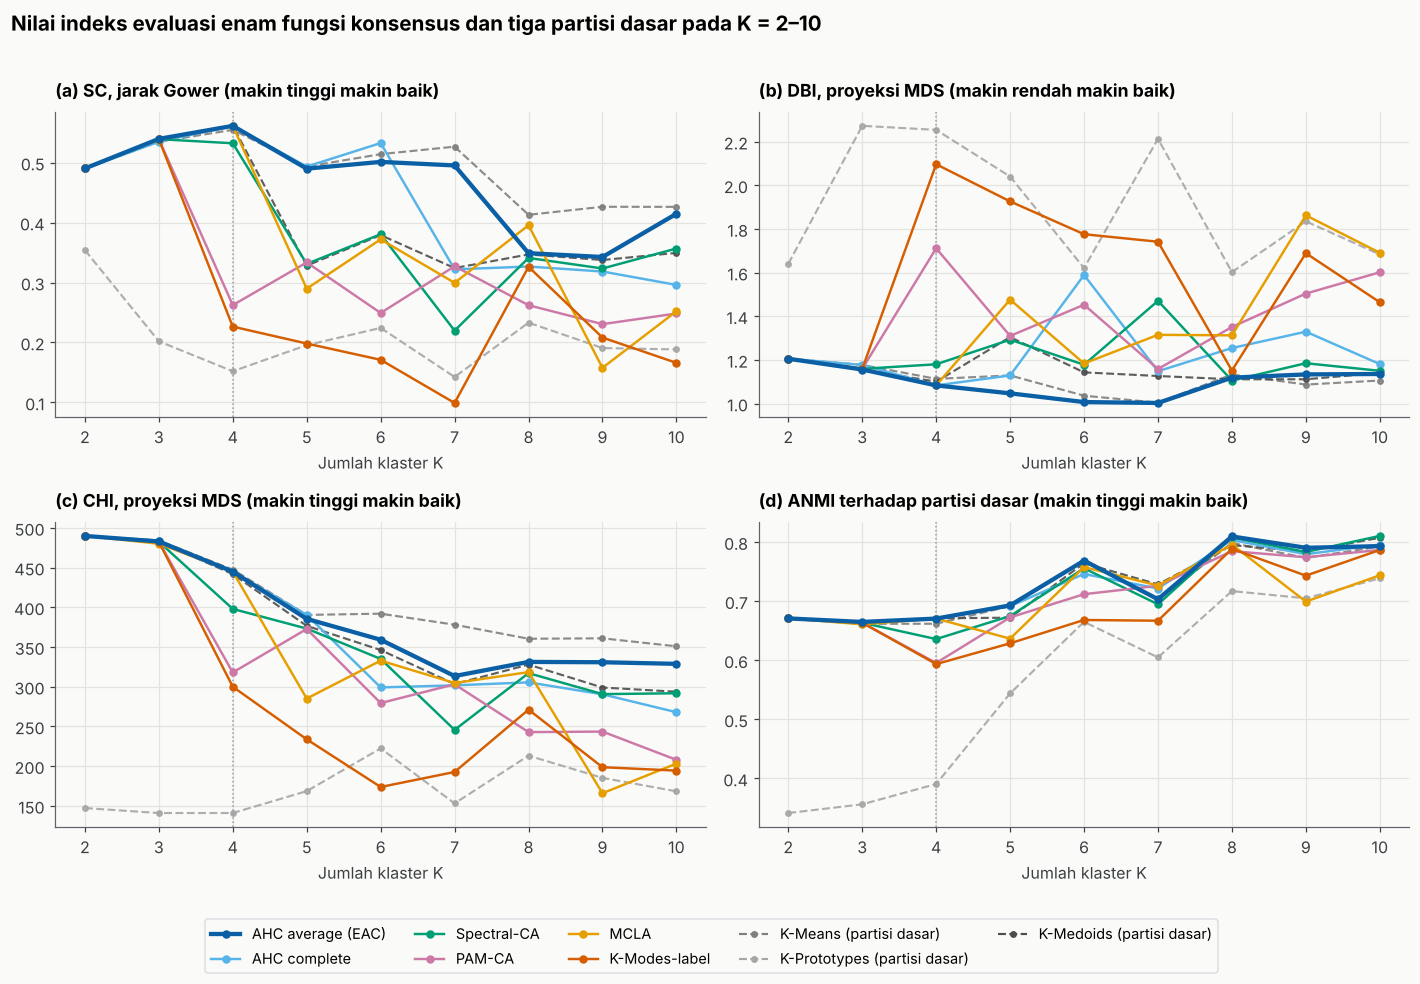

Garis titik-titik: K = 4. EAC pada K = 4 → SC 0,5612, DBI 1,0829, CHI 444,88, ANMI 0,6705


In [9]:
# Visualisasi 1 · SC, DBI, CHI, dan ANMI untuk K = 2–10 (enam fungsi konsensus dan tiga partisi dasar)
fig, axs = plt.subplots(2, 2, figsize=(13, 8.6))
panel = [("SC", "(a) SC, jarak Gower (makin tinggi makin baik)"), ("DBI", "(b) DBI, proyeksi MDS (makin rendah makin baik)"),
         ("CHI", "(c) CHI, proyeksi MDS (makin tinggi makin baik)"), ("ANMI", "(d) ANMI terhadap partisi dasar (makin tinggi makin baik)")]
for ax, (m, judul) in zip(axs.flat, panel):
    for a in B3:
        e = EV[(EV.Jenis == "Base") & (EV.Metode == a)].sort_values("K")
        ax.plot(e.K, e[m], ls="--", lw=1.4, marker="o", ms=3.5, color=WARNA_BASE[a], alpha=0.9)
    for i, c in enumerate(CONS6):
        e = EV[(EV.Jenis == "Konsensus") & (EV.Metode == c)].sort_values("K")
        lw, z = (2.8, 5) if c == "AHC average" else (1.6, 3)
        ax.plot(e.K, e[m], lw=lw, marker="o", ms=4.5, color=WARNA_FUNGSI[c], zorder=z)
    ax.axvline(4, color="#9AA0A6", lw=1, ls=":"); ax.set_title(judul, fontsize=11.5); ax.set_xticks(KS); ax.set_xlabel("Jumlah klaster K")
leg = [Line2D([], [], color=WARNA_FUNGSI[c], lw=2.8 if c == "AHC average" else 1.6, marker="o", ms=4.5, label=LABEL_FUNGSI[c]) for c in CONS6]
leg += [Line2D([], [], color=WARNA_BASE[a], lw=1.4, ls="--", marker="o", ms=3.5, label=f"{a} (partisi dasar)") for a in B3]
fig.legend(handles=leg, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.045), fontsize=9.5)
fig.suptitle("Nilai indeks evaluasi enam fungsi konsensus dan tiga partisi dasar pada K = 2–10", x=0.01, ha="left", fontweight="bold", fontsize=13.5)
fig.tight_layout(rect=(0, 0.04, 1, 0.97)); simpan(fig, "V1_indeks_evaluasi_K2-10.png"); plt.show()
e4 = EV[(EV.K == 4) & (EV.Metode == "AHC average")].iloc[0]
print(f"Garis titik-titik: K = 4. EAC pada K = 4 → SC {koma(e4.SC, 4)}, DBI {koma(e4.DBI, 4)}, CHI {koma(e4.CHI)}, ANMI {koma(e4.ANMI, 4)}")


# BAGIAN 5 · Peringkat per K, kepekaan ruang evaluasi, dan protokol K
**Protokol K:** fungsi dibandingkan pada K tetap = 3 dan 4. Alasannya: (1) jumlah skor komposit lintas 6 fungsi terendah pada K = 3 dan K = 4 termasuk terendah berikutnya; (2) K optimal setiap fungsi hanya jatuh pada K = 3 atau 4; (3) lifetime dendrogram AHC average paling panjang pada K = 4. Hasil K = 2–10 tetap dilaporkan sebagai pelengkap.

In [10]:
KRIT = {"SC": False, "DBI": True, "CHI": False, "ANMI": False, "SC Euclid": False}
rows = []
for K in KS:
    e = EV[(EV.K == K) & (EV.Jenis == "Konsensus")].set_index("Metode").loc[CONS6]
    for c in CONS6: rows.append({"K": K, "Metode": c, **{f"peringkat {k}": e[k].rank(ascending=asc, method="average")[c] for k, asc in KRIT.items()}})
RK = pd.DataFrame(rows); RK["rata-rata peringkat (SC, DBI, CHI, ANMI)"] = RK[["peringkat SC", "peringkat DBI", "peringkat CHI", "peringkat ANMI"]].mean(1)

SP = []
for K in KS:
    e = EV[(EV.K == K) & (EV.Jenis == "Konsensus")].set_index("Metode").loc[CONS6]; rho, p = spearmanr(e.SC, e["SC Euclid"])
    SP.append({"K": K, "Spearman ρ (SC Gower vs SC Euclid, 6 fungsi)": rho, "p-value": p, "terbaik SC Gower": e.SC.idxmax(), "terbaik SC Euclid": e["SC Euclid"].idxmax()})
SP = pd.DataFrame(SP)

KC = pd.DataFrame({c: peringkat_komposit(EV[EV.Metode == c][["K", "SC", "DBI", "CHI"]]).set_index("K").Peringkat_Komposit for c in CONS6}).loc[KS]
KC["Jumlah (6 fungsi)"] = KC.sum(1); KOPT = {c: int(KC[c].idxmin()) for c in CONS6}
Cm4 = coassoc(MAIN[4]["P"], B3); Dj4 = 1 - Cm4; np.fill_diagonal(Dj4, 0); Dj4 = ((Dj4 + Dj4.T) / 2).astype(float)
hgt = linkage(squareform(Dj4, checks=False), "average")[:, 2]; n = len(X)
KC["lifetime AHC average"] = [hgt[n - K] - hgt[n - K - 1] for K in KS]
KC["K optimal untuk fungsi"] = [", ".join(c for c, k in KOPT.items() if k == K) for K in KS]
PROTOKOL = KC.reset_index().rename(columns={"index": "K"})
print("K optimal per fungsi:", KOPT); display(PROTOKOL.round(4)); display(SP.round(3))

K optimal per fungsi: {'AHC average': 4, 'AHC complete': 4, 'Spectral (C)': 3, 'K-Medoids (1-C)': 3, 'MCLA': 4, 'K-Modes (label)': 3}


,K,AHC average,AHC complete,Spectral (C),K-Medoids (1-C),MCLA,K-Modes (label),Jumlah (6 fungsi),lifetime AHC average,K optimal untuk fungsi
0,2,15.0,12.0,11.0,6.0,8.0,6.0,58.0,0.0341,
1,3,12.0,8.0,6.0,5.0,6.0,5.0,42.0,0.0136,"Spectral (C), K-Medoids (1-C), K-Modes (label)"
2,4,8.0,5.0,10.0,18.0,5.0,16.0,62.0,0.4919,"AHC average, AHC complete, MCLA"
3,5,13.0,10.0,19.0,10.0,21.0,19.0,92.0,0.0071,
4,6,10.0,19.0,13.0,19.0,12.0,23.0,96.0,0.0448,
5,7,14.0,16.0,27.0,10.0,18.0,23.0,108.0,0.0000,
6,8,19.0,18.0,13.0,19.0,14.0,8.0,91.0,0.0000,
7,9,22.0,24.0,22.0,23.0,27.0,16.0,134.0,0.0000,
8,10,22.0,23.0,14.0,25.0,24.0,19.0,127.0,0.0000,


,K,"Spearman ρ (SC Gower vs SC Euclid, 6 fungsi)",p-value,terbaik SC Gower,terbaik SC Euclid
0,2,NaN,NaN,AHC average,AHC average
1,3,1.000,0.000,AHC average,AHC average
2,4,1.000,0.000,AHC average,AHC average
3,5,1.000,0.000,AHC complete,AHC complete
4,6,1.000,0.000,AHC complete,AHC complete
5,7,1.000,0.000,AHC average,AHC average
6,8,1.000,0.000,MCLA,MCLA
7,9,0.943,0.005,AHC average,AHC average
8,10,0.943,0.005,AHC average,AHC average


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V2_pemilihan_K_EAC.png


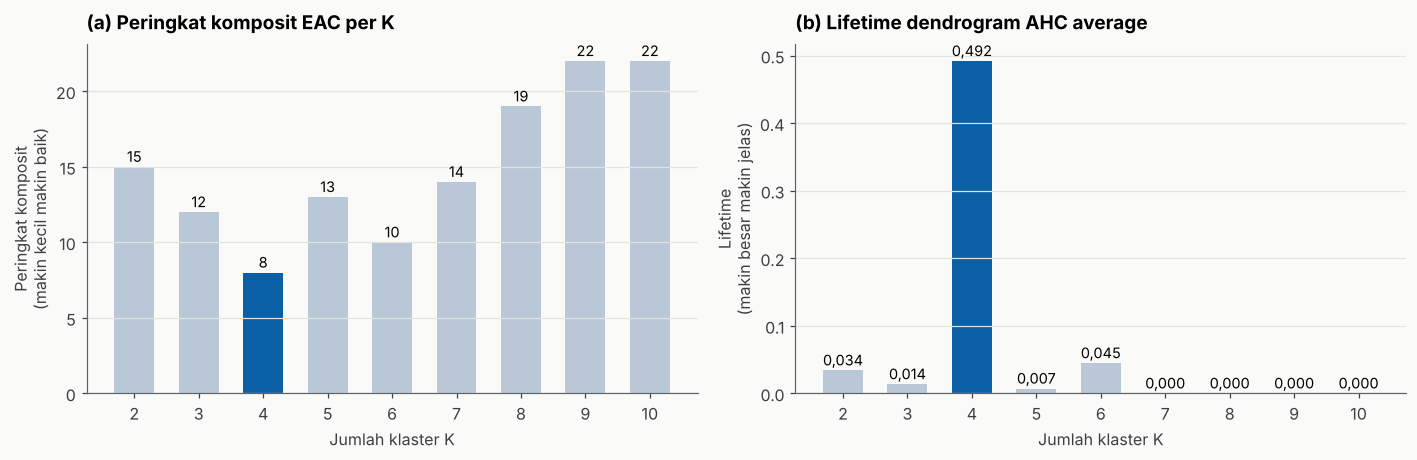

K terbaik EAC (peringkat komposit): 4 | K dengan lifetime terbesar: 4


In [11]:
# Visualisasi 2 · Pemilihan K untuk EAC: peringkat komposit (SC, DBI, CHI) dan lifetime dendrogram AHC average
kc = PROTOKOL.set_index("K")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, kol, judul, lab, fmt in [(axs[0], "AHC average", "(a) Peringkat komposit EAC per K", "Peringkat komposit\n(makin kecil makin baik)", "{:.0f}"),
                                  (axs[1], "lifetime AHC average", "(b) Lifetime dendrogram AHC average", "Lifetime\n(makin besar makin jelas)", "{:.3f}")]:
    best = kc[kol].idxmin() if kol == "AHC average" else kc[kol].idxmax()
    bars = ax.bar(kc.index.astype(str), kc[kol], color=["#0B5FA5" if K == best else "#B9C7D8" for K in kc.index], width=0.62)
    for bb, v in zip(bars, kc[kol]): ax.text(bb.get_x() + bb.get_width() / 2, v + kc[kol].max() * 0.015, fmt.format(v).replace(".", ","), ha="center", fontsize=9.5)
    ax.set_xlabel("Jumlah klaster K"); ax.set_ylabel(lab); ax.set_title(judul); ax.grid(axis="x", visible=False)
fig.tight_layout(); simpan(fig, "V2_pemilihan_K_EAC.png"); plt.show()
print("K terbaik EAC (peringkat komposit):", int(kc["AHC average"].idxmin()), "| K dengan lifetime terbesar:", int(kc["lifetime AHC average"].idxmax()))


# BAGIAN 6 · Lapis 1 — ketahanan terhadap inisialisasi acak
Seluruh proses (3 base + 6 fungsi) diulang dengan seed 0–29 pada K = 3 dan 4. Stabilitas = rata-rata ARI antar-pasangan seed (435 pasangan).

In [12]:
def _job_l1(Xd, K, s):
    Dm = gower_of(Xd); P = base3(Xd, Dm, K, s); out = konsensus6(P, B3, K, s)
    return K, s, dict(P=P, out=out)
def _lapis1():
    res = Parallel(n_jobs=N_JOBS)(delayed(_job_l1)(X, K, s) for K in K_UJI for s in range(N_REP))
    return {K: [r for k, s, r in sorted(res, key=lambda t: (t[0], t[1])) if k == K] for K in K_UJI}
L1 = dengan_checkpoint("lapis1", buat_sidik("l1", X, K_UJI, N_REP, CONS6), _lapis1)
def stabil(H):
    pr = [adjusted_rand_score(H[i], H[j]) for i, j in combinations(range(len(H)), 2)]; return np.mean(pr), np.min(pr), np.max(pr)
rows = []
for K in K_UJI:
    for c in CONS6:
        H = [r["out"][c] for r in L1[K]]; m, mn, mx = stabil(H)
        rows.append({"K": K, "Metode": c, "ARI rata-rata (stabilitas)": m, "ARI terkecil": mn, "ARI terbesar": mx,
                     "ARI rata-rata vs hasil utama": np.mean([adjusted_rand_score(h, MAIN[K]["out"][c]) for h in H]),
                     "SC rata-rata": np.mean([evaluasi(h)["SC"] for h in H]), "ANMI rata-rata": np.mean([anmi(r["out"][c], r["P"], B3) for r in L1[K]])})
L1T = pd.DataFrame(rows); display(L1T.round(4))

ℹ 'lapis1' dibaca dari checkpoint


,K,Metode,ARI rata-rata (stabilitas),ARI terkecil,ARI terbesar,ARI rata-rata vs hasil utama,SC rata-rata,ANMI rata-rata
0,3,AHC average,1.0000,1.0000,1.0000,1.0000,0.5395,0.6621
1,3,AHC complete,1.0000,1.0000,1.0000,1.0000,0.5347,0.6595
2,3,Spectral (C),0.9964,0.9903,1.0000,0.9925,0.5360,0.6546
3,3,K-Medoids (1-C),0.9957,0.9885,1.0000,0.9912,0.5357,0.6600
4,3,MCLA,0.9953,0.9899,1.0000,0.9954,0.5382,0.6585
5,3,K-Modes (label),0.8268,0.3671,1.0000,0.9023,0.4856,0.6409
6,4,AHC average,0.9962,0.9767,1.0000,0.9928,0.5611,0.6808
7,4,AHC complete,0.9619,0.9189,1.0000,0.9668,0.5074,0.6631
8,4,Spectral (C),0.9549,0.9067,1.0000,0.9591,0.5446,0.6591
9,4,K-Medoids (1-C),0.7441,0.4656,1.0000,0.7953,0.2378,0.6052


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V3_kestabilan_seed_K4.png


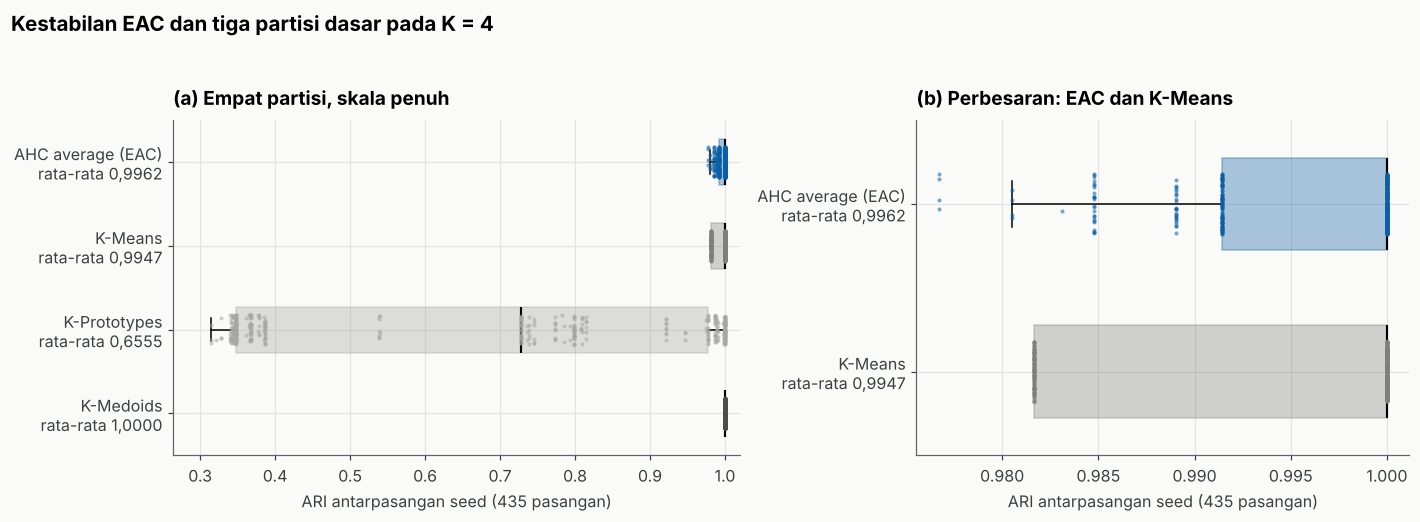

{'AHC average (EAC)': '0,9962', 'K-Means': '0,9947', 'K-Prototypes': '0,6555', 'K-Medoids': '1,0000'}


In [13]:
# Visualisasi 3 · Kestabilan EAC dan tiga partisi dasar terhadap 30 seed (K = 4)
from itertools import combinations as _comb
def _ari_pasangan(H): return [adjusted_rand_score(H[i], H[j]) for i, j in _comb(range(len(H)), 2)]
ST = {"AHC average (EAC)": _ari_pasangan([r["out"]["AHC average"] for r in L1[4]])}
for a in B3: ST[a] = _ari_pasangan([r["P"][a] for r in L1[4]])
nama = list(ST); warna = ["#0B5FA5"] + [WARNA_BASE[a] for a in B3]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, judul, zoom in [(axs[0], "(a) Empat partisi, skala penuh", False), (axs[1], "(b) Perbesaran: EAC dan K-Means", True)]:
    pilih = [n for n in nama if (not zoom) or n in ("AHC average (EAC)", "K-Means")]
    data = [ST[n] for n in pilih]; wr = [warna[nama.index(n)] for n in pilih]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.55, showfliers=False, medianprops=dict(color="black", lw=1.4))
    for p, w in zip(bp["boxes"], wr): p.set_facecolor(w); p.set_alpha(0.35); p.set_edgecolor(w)
    rng = np.random.default_rng(0)
    for i, (d, w) in enumerate(zip(data, wr), 1):
        ax.scatter(d, i + rng.uniform(-0.18, 0.18, len(d)), s=7, color=w, alpha=0.55, lw=0, zorder=3)
    ax.set_yticks(range(1, len(pilih) + 1), [f"{n}\nrata-rata {koma(np.mean(ST[n]), 4)}" for n in pilih]); ax.set_xlabel("ARI antarpasangan seed (435 pasangan)"); ax.set_title(judul); ax.invert_yaxis()
    if not zoom: ax.set_xlim(min(map(min, data)) - 0.05, 1.02)
fig.suptitle("Kestabilan EAC dan tiga partisi dasar pada K = 4", x=0.01, ha="left", fontweight="bold", fontsize=13.5)
fig.tight_layout(rect=(0, 0, 1, 0.95)); simpan(fig, "V3_kestabilan_seed_K4.png"); plt.show()
print({n: koma(np.mean(v), 4) for n, v in ST.items()})


# BAGIAN 7 · Lapis 2 — ketahanan terhadap cara membangkitkan ensemble
33 partisi (3 model × 11 replikasi, `n_init` = 1). Skema **Seed saja** dan **Subsampel objek** (80% objek, sisanya ke pusat/medoid/prototipe terdekat) = uji utama; **Subruang variabel** (6 dari 9 variabel, minimal 1 biner) dan **Subruang + subsampel** = uji tekanan.

In [14]:
SKEMA = ["Seed saja", "Subruang variabel", "Subsampel objek", "Subruang + subsampel"]; R_PER_MODEL = 11
def per_variabel(Xd):
    DK = []
    for c in NUMERIK:
        v = Xd[c].to_numpy(float); DK.append((np.abs(v[:, None] - v[None, :]) / (v.max() - v.min())).astype(np.float32))
    for c in BINER:
        v = Xd[c].to_numpy(float); DK.append((v[:, None] != v[None, :]).astype(np.float32))
    return np.array(DK)
def satu_partisi(Xd, DK, model, K, sub_fitur, sub_obj, seed):
    Xa = Xd.to_numpy(float); n = len(Xa); rng = np.random.default_rng(seed)
    if sub_fitur:
        while True:
            f = np.sort(rng.choice(9, 6, replace=False))
            if any(i >= 6 for i in f): break
    else: f = np.arange(9)
    idx = np.sort(rng.choice(n, int(0.8 * n), replace=False)) if sub_obj else np.arange(n); rest = np.setdiff1d(np.arange(n), idx)
    lab = np.full(n, -1)
    if model == "K-Means":
        km = KMeans(K, n_init=1, random_state=seed).fit(Xa[idx][:, f]); lab[idx] = km.labels_
        if len(rest): lab[rest] = km.predict(Xa[rest][:, f])
    elif model == "K-Medoids":
        Ds = DK[f].mean(0).astype(float); np.fill_diagonal(Ds, 0)
        res = kmedoids.pam(Ds[np.ix_(idx, idx)], K, init="random", random_state=seed); lab[idx] = np.asarray(res.labels)
        if len(rest): lab[rest] = Ds[np.ix_(rest, idx[np.asarray(res.medoids)])].argmin(1)
    else:
        num = [i for i in f if i < 6]; bn = [i for i in f if i >= 6]
        M = np.hstack([Xa[:, num], np.where(Xa[:, bn] == 1, "YA", "TIDAK").astype(object)]); cat = list(range(len(num), len(num) + len(bn))); kp = None
        for init in ("Huang", "Cao"):
            try: kp = KPrototypes(n_clusters=K, init=init, n_init=1, random_state=seed, verbose=0).fit(M[idx], categorical=cat); break
            except ValueError: continue
        lab[idx] = kp.labels_
        if len(rest): lab[rest] = kp.predict(M[rest], categorical=cat)
    return lab
def ensemble(Xd, DK, K, skema, master):
    sf = skema in ("Subruang variabel", "Subruang + subsampel"); so = skema in ("Subsampel objek", "Subruang + subsampel"); parts, names = {}, []
    for mi, m in enumerate(B3):
        for r in range(R_PER_MODEL):
            nm = f"{m}#{r+1}"; parts[nm] = satu_partisi(Xd, DK, m, K, sf, so, master * 100003 + mi * 1009 + r * 17 + K).astype(int); names.append(nm)
    return parts, names
def _job_l2(Xd, sk, K, s):
    DK = per_variabel(Xd); parts, names = ensemble(Xd, DK, K, sk, s); out = konsensus6(parts, names, K, s)
    return (sk, K, s), dict(out={c: out[c].astype(np.int16) for c in CONS6}, parts={k: v.astype(np.int16) for k, v in parts.items()}, names=names)
def _lapis2():
    tugas = [(sk, K, RANDOM_STATE) for sk in SKEMA for K in KS] + [(sk, K, s) for K in K_UJI for sk in SKEMA for s in range(N_REP)]
    return dict(Parallel(n_jobs=N_JOBS, verbose=2)(delayed(_job_l2)(X, sk, K, s) for sk, K, s in tugas))
L2 = dengan_checkpoint("lapis2", buat_sidik("l2", X, SKEMA, KS, K_UJI, N_REP, R_PER_MODEL, CONS6), _lapis2)
def _parts(r): return {k: v.astype(int) for k, v in r["parts"].items()}
rows = []
for sk in SKEMA:
    for K in KS:
        r = L2[(sk, K, RANDOM_STATE)]; P = _parts(r)
        for c in CONS6: rows.append({"Skema perturbasi": sk, "K": K, "Metode": c, **eval_lengkap(r["out"][c].astype(int), P, r["names"]),
                                     "ARI terhadap hasil utama 3 base": adjusted_rand_score(r["out"][c], MAIN[K]["out"][c])})
L2E = pd.DataFrame(rows)
L2SC = {(sk, K, s): {c: (evaluasi(L2[(sk, K, s)]["out"][c].astype(int))["SC"], anmi(L2[(sk, K, s)]["out"][c].astype(int), _parts(L2[(sk, K, s)]), L2[(sk, K, s)]["names"])) for c in CONS6}
        for K in K_UJI for sk in SKEMA for s in range(N_REP)}
rows = []
for K in K_UJI:
    for sk in SKEMA:
        for c in CONS6:
            H = [L2[(sk, K, s)]["out"][c].astype(int) for s in range(N_REP)]; m, mn, mx = stabil(H)
            rows.append({"K": K, "Skema perturbasi": sk, "Peran": "utama" if sk in ("Seed saja", "Subsampel objek") else "uji tekanan", "Metode": c,
                         "ARI rata-rata (stabilitas)": m, "ARI terkecil": mn, "ARI terbesar": mx,
                         "ARI rata-rata vs hasil utama 3 base": np.mean([adjusted_rand_score(h, MAIN[K]["out"][c]) for h in H]),
                         "SC rata-rata": np.mean([L2SC[(sk, K, s)][c][0] for s in range(N_REP)]), "ANMI rata-rata": np.mean([L2SC[(sk, K, s)][c][1] for s in range(N_REP)])})
L2S = pd.DataFrame(rows); display(L2S[L2S.K == 4].round(4))

ℹ 'lapis2' dibaca dari checkpoint


,K,Skema perturbasi,Peran,Metode,ARI rata-rata (stabilitas),ARI terkecil,ARI terbesar,ARI rata-rata vs hasil utama 3 base,SC rata-rata,ANMI rata-rata
24,4,Seed saja,utama,AHC average,0.9761,0.7375,1.0000,0.9844,0.5565,0.6560
25,4,Seed saja,utama,AHC complete,0.9973,0.9825,1.0000,0.9947,0.5611,0.6554
26,4,Seed saja,utama,Spectral (C),0.7364,0.4797,1.0000,0.7960,0.4485,0.6239
27,4,Seed saja,utama,K-Medoids (1-C),0.7950,0.5196,1.0000,0.5565,0.3344,0.5921
28,4,Seed saja,utama,MCLA,0.9534,0.7732,1.0000,0.9723,0.5506,0.6516
29,4,Seed saja,utama,K-Modes (label),0.6043,0.2231,1.0000,0.4896,0.2385,0.4739
30,4,Subruang variabel,uji tekanan,AHC average,0.7781,0.3328,1.0000,0.8473,0.5239,0.5144
31,4,Subruang variabel,uji tekanan,AHC complete,0.8893,0.3528,1.0000,0.9256,0.5434,0.5134
32,4,Subruang variabel,uji tekanan,Spectral (C),0.6654,0.3346,0.9964,0.6003,0.3613,0.4980
33,4,Subruang variabel,uji tekanan,K-Medoids (1-C),0.8160,0.4358,1.0000,0.4544,0.3160,0.4780


# BAGIAN 8 · Lapis 3 — ketahanan terhadap data
(a) **Subsampel 80%** UMKM × 30 (Min-Max dan Gower dihitung ulang pada subsampel); (b) **derau biner 5%**: tiap nilai biner dibalik dengan peluang 5%, × 30. Seed algoritma tetap 42, sehingga variasi hanya berasal dari data. ARI dihitung terhadap hasil data penuh pada UMKM yang sama.

In [15]:
def _job_l3(Xd, jenis, K, r):
    rng = np.random.default_rng(1000 + r); n = len(Xd)
    if jenis == "Subsampel 80%":
        idx = np.sort(rng.choice(n, int(0.8 * n), replace=False)); Xs = Xd.iloc[idx].copy()
        for c in NUMERIK: Xs[c] = (Xs[c] - Xs[c].min()) / (Xs[c].max() - Xs[c].min())
    else:
        idx = np.arange(n); Xs = Xd.copy()
        for c in BINER: flip = rng.random(n) < 0.05; Xs[c] = np.where(flip, 1 - Xs[c], Xs[c])
    Dm = gower_of(Xs); P = base3(Xs, Dm, K, RANDOM_STATE); out = konsensus6(P, B3, K, RANDOM_STATE)
    return (jenis, K, r), dict(idx=idx, out=out, P=P)
GANGGUAN = ["Subsampel 80%", "Derau biner 5%"]
L3 = dengan_checkpoint("lapis3", buat_sidik("l3", X, K_UJI, N_REP, CONS6), lambda: dict(Parallel(n_jobs=N_JOBS)(delayed(_job_l3)(X, j, K, r) for j in GANGGUAN for K in K_UJI for r in range(N_REP))))
rows, rr = [], []
for j in GANGGUAN:
    for K in K_UJI:
        for nama, ambil in [(c, lambda o, c=c: o["out"][c]) for c in CONS6] + [(f"(base) {b}", lambda o, b=b: o["P"][b]) for b in B3]:
            ref = MAIN[K]["out"][nama] if nama in CONS6 else MAIN[K]["P"][nama.replace("(base) ", "")]
            a = [adjusted_rand_score(ambil(L3[(j, K, r)]), ref[L3[(j, K, r)]["idx"]]) for r in range(N_REP)]
            rows.append({"Gangguan data": j, "K": K, "Metode": nama, "ARI rata-rata vs data penuh": np.mean(a), "simpangan baku": np.std(a, ddof=1),
                         "ARI terkecil": np.min(a), "ARI terbesar": np.max(a), "replikasi dengan ARI ≥ 0,90": int((np.array(a) >= 0.9).sum())})
L3T = pd.DataFrame(rows); display(L3T[L3T.K == 4].round(4))

ℹ 'lapis3' dibaca dari checkpoint


,Gangguan data,K,Metode,ARI rata-rata vs data penuh,simpangan baku,ARI terkecil,ARI terbesar,"replikasi dengan ARI ≥ 0,90"
9,Subsampel 80%,4,AHC average,0.9451,0.1014,0.5072,0.9972,23
10,Subsampel 80%,4,AHC complete,0.9480,0.1224,0.4630,0.9972,27
11,Subsampel 80%,4,Spectral (C),0.8321,0.1730,0.5090,0.9845,23
12,Subsampel 80%,4,K-Medoids (1-C),0.5345,0.1130,0.4095,0.8592,0
13,Subsampel 80%,4,MCLA,0.8661,0.2162,0.4567,0.9962,23
14,Subsampel 80%,4,K-Modes (label),0.5105,0.0783,0.4316,0.8040,0
15,Subsampel 80%,4,(base) K-Means,0.9818,0.0102,0.9640,0.9970,30
16,Subsampel 80%,4,(base) K-Prototypes,0.4250,0.1371,0.2277,0.7728,0
17,Subsampel 80%,4,(base) K-Medoids,0.8883,0.2033,0.5145,1.0000,23
27,Derau biner 5%,4,AHC average,0.6875,0.0220,0.6300,0.7233,0


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V4_peta_ketahanan_K4.png


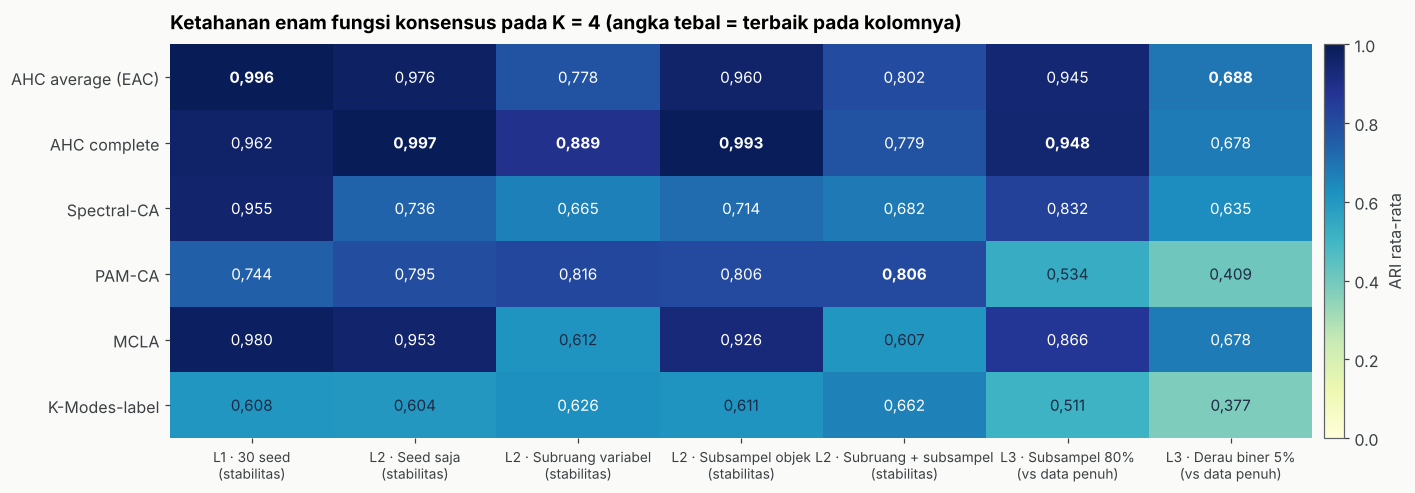

In [16]:
# Visualisasi 4 · Peta panas ketahanan enam fungsi konsensus pada K = 4 (Lapis 1–3)
kol = {}
t = L1T[L1T.K == 4].set_index("Metode"); kol["L1 · 30 seed\n(stabilitas)"] = t["ARI rata-rata (stabilitas)"]
for sk in ["Seed saja", "Subruang variabel", "Subsampel objek", "Subruang + subsampel"]:
    t = L2S[(L2S.K == 4) & (L2S["Skema perturbasi"] == sk)].set_index("Metode"); kol[f"L2 · {sk}\n(stabilitas)"] = t["ARI rata-rata (stabilitas)"]
for g in ["Subsampel 80%", "Derau biner 5%"]:
    t = L3T[(L3T.K == 4) & (L3T["Gangguan data"] == g)].set_index("Metode"); kol[f"L3 · {g}\n(vs data penuh)"] = t["ARI rata-rata vs data penuh"]
HM = pd.DataFrame(kol).loc[CONS6]; HM.index = [LABEL_FUNGSI[c] for c in CONS6]
fig, ax = plt.subplots(figsize=(13, 4.6))
im = ax.imshow(HM.values, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
for i in range(HM.shape[0]):
    for j in range(HM.shape[1]):
        v = HM.values[i, j]; best = np.isclose(v, HM.values[:, j].max())
        ax.text(j, i, koma(v, 3), ha="center", va="center", fontsize=10, color="white" if v > 0.62 else "#1F2A44", fontweight="bold" if best else "normal")
ax.set_xticks(range(HM.shape[1]), HM.columns, fontsize=9); ax.set_yticks(range(HM.shape[0]), HM.index); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.set_label("ARI rata-rata")
ax.set_title("Ketahanan enam fungsi konsensus pada K = 4 (angka tebal = terbaik pada kolomnya)")
fig.tight_layout(); simpan(fig, "V4_peta_ketahanan_K4.png"); plt.show()


# BAGIAN 9 · Uji Friedman–Nemenyi dengan replikasi sebagai blok
Satu uji per kombinasi lapis × kondisi × K × kriteria; blok = 30 replikasi independen. Kelompok teratas = fungsi yang selisih peringkatnya dari yang terbaik ≤ beda kritis Nemenyi (α = 0,05; q = 2,850 untuk 6 fungsi).

In [17]:
Q_NEMENYI = {5: 2.728, 6: 2.850, 7: 2.949}[len(CONS6)]       # Demšar (2006), α = 0,05
def uji_friedman(M, naik=True):
    N, k = M.shape; Rk = np.array([rankdata(-x if naik else x, method="average") for x in np.round(M, 10)]); mr = Rk.mean(0); cd = Q_NEMENYI * np.sqrt(k * (k + 1) / (6 * N))
    if np.allclose(Rk, Rk[0][0]): return mr, np.nan, np.nan, cd
    chi, p = friedmanchisquare(*Rk.T); return mr, chi, p, cd
DATA_UJI = []
for K in K_UJI:
    vals = {k: [] for k in ["SC", "DBI", "CHI", "ANMI", "ARI vs hasil utama"]}
    for r in L1[K]:
        e = {c: evaluasi(r["out"][c]) for c in CONS6}
        for k in ["SC", "DBI", "CHI"]: vals[k].append([e[c][k] for c in CONS6])
        vals["ANMI"].append([anmi(r["out"][c], r["P"], B3) for c in CONS6]); vals["ARI vs hasil utama"].append([adjusted_rand_score(r["out"][c], MAIN[K]["out"][c]) for c in CONS6])
    for k, v in vals.items(): DATA_UJI.append(("Lapis 1", "30 seed", "utama", K, k, k != "DBI", np.array(v)))
    for sk in SKEMA:
        peran = "utama" if sk in ("Seed saja", "Subsampel objek") else "uji tekanan"; R = [L2[(sk, K, s)] for s in range(N_REP)]
        DATA_UJI.append(("Lapis 2", sk, peran, K, "SC", True, np.array([[L2SC[(sk, K, s)][c][0] for c in CONS6] for s in range(N_REP)])))
        DATA_UJI.append(("Lapis 2", sk, peran, K, "ANMI", True, np.array([[L2SC[(sk, K, s)][c][1] for c in CONS6] for s in range(N_REP)])))
        DATA_UJI.append(("Lapis 2", sk, peran, K, "ARI vs hasil utama", True, np.array([[adjusted_rand_score(r["out"][c], MAIN[K]["out"][c]) for c in CONS6] for r in R])))
    for j in GANGGUAN:
        R = [L3[(j, K, r)] for r in range(N_REP)]
        DATA_UJI.append(("Lapis 3", j, "utama", K, "ARI vs data penuh", True, np.array([[adjusted_rand_score(r["out"][c], MAIN[K]["out"][c][r["idx"]]) for c in CONS6] for r in R])))
        DATA_UJI.append(("Lapis 3", j, "utama", K, "ANMI", True, np.array([[anmi(r["out"][c], r["P"], B3) for c in CONS6] for r in R])))
rows, blok = [], []
for lap, kon, peran, K, kr, naik, M in DATA_UJI:
    mr, chi, p, cd = uji_friedman(M, naik); best = mr.min()
    top = CONS6 if (np.isnan(chi) or p >= 0.05) else [c for i, c in enumerate(CONS6) if mr[i] - best <= cd]
    r = {"Lapis": lap, "Kondisi": kon, "Peran": peran, "K": K, "Kriteria": kr, "Arah": "naik = baik" if naik else "turun = baik", "Blok (N replikasi)": len(M),
         "Friedman χ²": chi, "p-value": p, "Signifikan (p < 0,05)": "—" if np.isnan(chi) else ("ya" if p < 0.05 else "tidak"), "CD Nemenyi (α = 0,05)": cd,
         "Peringkat terbaik": ", ".join(SINGKAT[c] for i, c in enumerate(CONS6) if mr[i] == best),
         "Kelompok teratas (tidak berbeda nyata dari terbaik)": ", ".join(SINGKAT[c] for c in top)}
    r.update({f"peringkat {SINGKAT[c]}": mr[i] for i, c in enumerate(CONS6)}); r.update({f"rata-rata {SINGKAT[c]}": M[:, i].mean() for i, c in enumerate(CONS6)})
    rows.append(r)
    for b in range(len(M)): blok.append({"Lapis": lap, "Kondisi": kon, "K": K, "Kriteria": kr, "Replikasi": b + 1, **{SINGKAT[c]: M[b, i] for i, c in enumerate(CONS6)}})
FRR = pd.DataFrame(rows); BLK = pd.DataFrame(blok)
tal = []
for cak in ("utama", "uji tekanan", "semua"):
    f = FRR[(FRR["Signifikan (p < 0,05)"] == "ya") & ((FRR.Peran == cak) if cak != "semua" else True)]
    for c in CONS6:
        tal.append({"Cakupan uji": cak, "Metode": c, "uji signifikan": len(f),
                    "masuk kelompok teratas": int(f["Kelompok teratas (tidak berbeda nyata dari terbaik)"].str.split(", ").apply(lambda L: SINGKAT[c] in L).sum()),
                    "peringkat terbaik (termasuk seri)": int(f["Peringkat terbaik"].str.split(", ").apply(lambda L: SINGKAT[c] in L).sum()),
                    "peringkat rata-rata antar uji": f[f"peringkat {SINGKAT[c]}"].mean()})
TAL = pd.DataFrame(tal); TAL["% kelompok teratas"] = TAL["masuk kelompok teratas"] / TAL["uji signifikan"] * 100
print(f"{len(FRR)} uji; {int((FRR['Signifikan (p < 0,05)'] == 'ya').sum())} signifikan"); display(TAL[TAL["Cakupan uji"] == "semua"].round(2))

42 uji; 42 signifikan


,Cakupan uji,Metode,uji signifikan,masuk kelompok teratas,peringkat terbaik (termasuk seri),peringkat rata-rata antar uji,% kelompok teratas
12,semua,AHC average,42,41,34,1.89,97.62
13,semua,AHC complete,42,30,13,2.80,71.43
14,semua,Spectral (C),42,13,4,3.58,30.95
15,semua,K-Medoids (1-C),42,9,4,4.05,21.43
16,semua,MCLA,42,15,0,3.54,35.71
17,semua,K-Modes (label),42,4,0,5.14,9.52


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V5_friedman_nemenyi.png


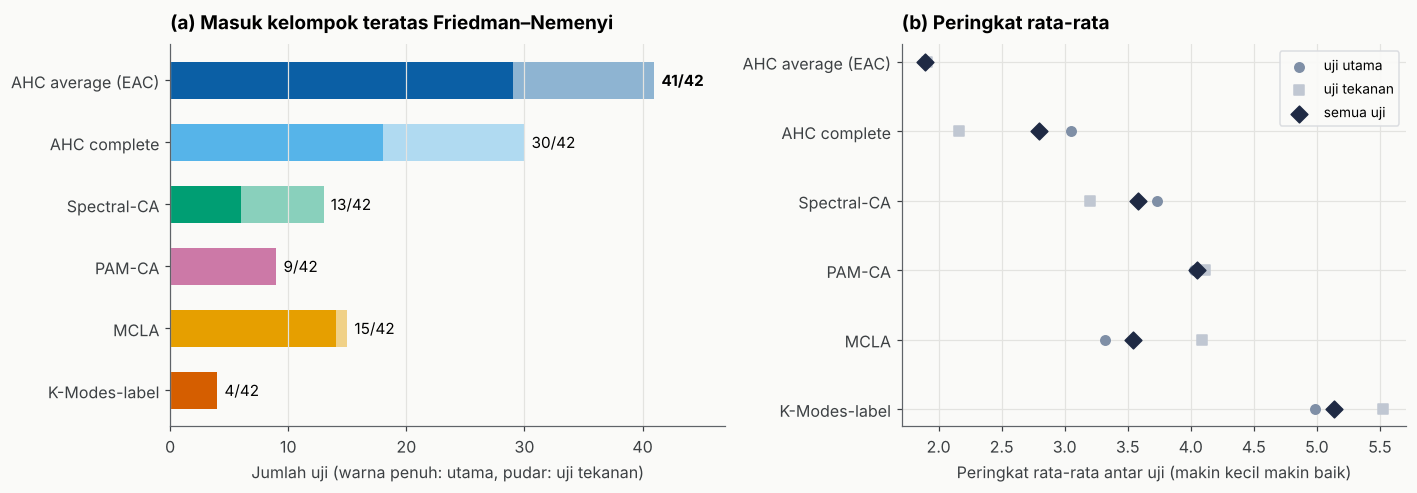

In [18]:
# Visualisasi 5 · Ringkasan uji Friedman–Nemenyi (42 uji: 30 uji utama dan 12 uji tekanan)
t = TAL[TAL["Cakupan uji"] == "semua"].set_index("Metode").loc[CONS6]
tu = TAL[TAL["Cakupan uji"] == "utama"].set_index("Metode").loc[CONS6]; tt = TAL[TAL["Cakupan uji"] == "uji tekanan"].set_index("Metode").loc[CONS6]
lab = [LABEL_FUNGSI[c] for c in CONS6]; y = np.arange(len(CONS6))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axs[0]
ax.barh(y, tu["masuk kelompok teratas"], color=[WARNA_FUNGSI[c] for c in CONS6], height=0.6, label="uji utama")
ax.barh(y, tt["masuk kelompok teratas"], left=tu["masuk kelompok teratas"], color=[WARNA_FUNGSI[c] for c in CONS6], alpha=0.45, height=0.6, label="uji tekanan")
for i, c in enumerate(CONS6):
    n = int(t.loc[c, "masuk kelompok teratas"]); tot = int(t.loc[c, "uji signifikan"])
    ax.text(n + 0.6, i, f"{n}/{tot}", va="center", fontsize=10, fontweight="bold" if c == "AHC average" else "normal")
ax.set_yticks(y, lab); ax.invert_yaxis(); ax.set_xlim(0, 47); ax.set_xlabel("Jumlah uji (warna penuh: utama, pudar: uji tekanan)")
ax.set_title("(a) Masuk kelompok teratas Friedman–Nemenyi"); ax.grid(axis="y", visible=False)
ax = axs[1]
for nm, d, mk in [("uji utama", tu, "o"), ("uji tekanan", tt, "s"), ("semua uji", t, "D")]:
    ax.scatter(d["peringkat rata-rata antar uji"], y, marker=mk, s=60 if nm == "semua uji" else 38, label=nm,
               color="#1F2A44" if nm == "semua uji" else ("#7F8FA6" if nm == "uji utama" else "#C0C7D2"), zorder=3)
ax.set_yticks(y, lab); ax.invert_yaxis(); ax.set_xlabel("Peringkat rata-rata antar uji (makin kecil makin baik)")
ax.set_title("(b) Peringkat rata-rata"); ax.legend(loc="upper right", fontsize=9)
fig.tight_layout(); simpan(fig, "V5_friedman_nemenyi.png"); plt.show()


# BAGIAN 10 · Simulasi semi-sintetis (validasi eksternal)
| | |
|---|---|
| **Generator** | Gaussian copula: laten L = a·Z[klaster] + E (E korelasi omset–biaya produksi dari data asli), lalu tiap variabel numerik dipetakan ke **kuantil empiris data asli** dan tiap biner diambang pada **proporsi asli**. Pusat klaster Z diacak (netral terhadap semua metode); ukuran klaster tidak seimbang meniru data asli (K = 3: 66/20/14%; K = 4: 60/20/13/7%). |
| **Faktor** | Sumber pemisah kelompok (**campuran**: numerik dan biner sama-sama membedakan kelompok · **terutama biner** · **terutama numerik**) × pemisahan (rendah / sedang / tinggi) × K benar (3 / 4) = 18 kondisi × 10 replikasi = **180 dataset** (n = 1.368). Semua dataset tetap berisi 6 variabel numerik dan 3 biner; faktor ini hanya mengatur variabel mana yang membedakan kelompok. |
| **Proses** | Pra-pemrosesan, 3 base, dan 6 fungsi persis sama dengan data asli; K diset sama dengan K benar. Algoritma tidak pernah melihat label kelompok; label hanya dipakai untuk menilai hasil (seperti kunci jawaban). |
| **Ukuran** | ARI dan NMI terhadap label benar; Friedman–Nemenyi dengan dataset sebagai blok. |

In [19]:
PROP = {3: [0.66, 0.20, 0.14], 4: [0.60, 0.20, 0.13, 0.07]}
LEVEL = {"campuran": {"rendah": (1.0, 1.0), "sedang": (1.5, 2.0), "tinggi": (3.5, 5.0)},       # (a_num, a_bin)
         "biner": {"rendah": (0.3, 1.5), "sedang": (0.5, 3.0), "tinggi": (1.2, 8.0)},
         "numerik": {"rendah": (2.0, 0.0), "sedang": (4.0, 0.0), "tinggi": (6.0, 0.0)}}
LABEL_SUMBER = {"campuran": "campuran", "biner": "terutama biner", "numerik": "terutama numerik"}
PARAM = {"emp": {c: np.sort(bersih[c].astype(float).to_numpy()) for c in NUMERIK}, "p": {c: float(bersih[c + "_BIN"].mean()) for c in BINER},
         "rho_ob": float(np.log1p(bersih[["OMSET", "BIAYA_PRODUKSI"]].astype(float)).corr().iloc[0, 1])}
def bangkitkan(P, K, a_num, a_bin, dom, n=1368, seed=0, d_min=1.5):
    rng = np.random.default_rng(seed)
    while True:
        Z = rng.standard_normal((K, 9)); part = Z[:, 6:] if dom == "biner" else (Z[:, :6] if dom == "numerik" else Z)
        dd = np.sqrt(((part[:, None] - part[None]) ** 2).sum(-1))[np.triu_indices(K, 1)]
        if dd.min() >= d_min and (dom != "biner" or len({tuple(r) for r in (Z[:, 6:] > 0)}) == K): break
    sz = np.round(np.array(PROP[K]) * n).astype(int); sz[0] += n - sz.sum(); y = np.repeat(np.arange(K), sz); rng.shuffle(y)
    E = rng.standard_normal((n, 9)); E[:, 3] = P["rho_ob"] * E[:, 2] + np.sqrt(1 - P["rho_ob"] ** 2) * E[:, 3]
    L = np.array([a_num] * 6 + [a_bin] * 3) * Z[y] + E; L = (L - L.mean(0)) / L.std(0); out = {}
    for j, c in enumerate(NUMERIK):
        emp = P["emp"][c]; out[c] = emp[np.clip((norm.cdf(L[:, j]) * len(emp)).astype(int), 0, len(emp) - 1)]
    for j, c in enumerate(BINER): out[c] = (L[:, 6 + j] > norm.ppf(1 - P["p"][c])).astype(float)
    return pd.DataFrame(out)[NUMERIK + BINER], y
def seed_sim(dom, lev, K, r):
    return 10000 * (["biner", "numerik", "campuran"].index(dom) + 1) + 1000 * ["rendah", "sedang", "tinggi"].index(lev) + 100 * K + r
def _job_sim(P, dom, lev, K, r):
    a_num, a_bin = LEVEL[dom][lev]; seed = seed_sim(dom, lev, K, r)
    rawd, y = bangkitkan(P, K, a_num, a_bin, dom, seed=seed); Xs = normalisasi(rawd[NUMERIK], rawd[BINER]); Dm = gower_of(Xs)
    Pp = base3(Xs, Dm, K, RANDOM_STATE); out = konsensus6(Pp, B3, K, RANDOM_STATE)
    row = {"Sumber pemisah": LABEL_SUMBER[dom], "Pemisahan": lev, "K benar": K, "Replikasi": r + 1, "seed data": seed}
    for c in CONS6: row[f"ARI {c}"] = adjusted_rand_score(y, out[c]); row[f"NMI {c}"] = normalized_mutual_info_score(y, out[c]); row[f"klaster terkecil {c}"] = int(np.bincount(out[c]).min())
    for b in B3: row[f"ARI base {b}"] = adjusted_rand_score(y, Pp[b])
    return row
TUGAS_SIM = [(dm, lv, K, r) for dm in ("campuran", "biner", "numerik") for lv in ("rendah", "sedang", "tinggi") for K in (3, 4) for r in range(10)]
SIM = dengan_checkpoint("simulasi", buat_sidik("sim", PARAM["p"], LEVEL, PROP, len(TUGAS_SIM), CONS6),
                        lambda: pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(_job_sim)(PARAM, *t) for t in TUGAS_SIM)))
ARI_COLS = [f"ARI {c}" for c in CONS6]
SIM_KOND = SIM.groupby(["Sumber pemisah", "Pemisahan", "K benar"], sort=False)[ARI_COLS + [f"ARI base {b}" for b in B3]].mean().reset_index()
SIM_KOND["konsensus terbaik (rata-rata ARI)"] = SIM_KOND[ARI_COLS].idxmax(1).str.replace("ARI ", "")
SIM_KOND["base terbaik (rata-rata ARI)"] = SIM_KOND[[f"ARI base {b}" for b in B3]].idxmax(1).str.replace("ARI base ", "")
rows = []
for nama, sub in [("Semua dataset", SIM)] + [(f"{d}", SIM[SIM["Sumber pemisah"] == d]) for d in SIM["Sumber pemisah"].unique()] + [(f"K benar = {K}", SIM[SIM["K benar"] == K]) for K in (3, 4)] \
                 + [(f"Pemisahan {lv}", SIM[SIM.Pemisahan == lv]) for lv in ("rendah", "sedang", "tinggi")]:
    for kr in ("ARI", "NMI"):
        M = sub[[f"{kr} {c}" for c in CONS6]].to_numpy(); mr, chi, p, cd = uji_friedman(M); best = mr.min()
        top = CONS6 if (np.isnan(chi) or p >= 0.05) else [c for i, c in enumerate(CONS6) if mr[i] - best <= cd]
        r = {"Kelompok dataset": nama, "Kriteria": kr, "Blok (N dataset)": len(M), "Friedman χ²": chi, "p-value": p, "CD Nemenyi (α = 0,05)": cd,
             "Peringkat terbaik": ", ".join(SINGKAT[c] for i, c in enumerate(CONS6) if mr[i] == best),
             "Kelompok teratas (tidak berbeda nyata dari terbaik)": ", ".join(SINGKAT[c] for c in top)}
        r.update({f"peringkat {SINGKAT[c]}": mr[i] for i, c in enumerate(CONS6)}); r.update({f"rata-rata {SINGKAT[c]}": M[:, i].mean() for i, c in enumerate(CONS6)})
        rows.append(r)
SIM_FR = pd.DataFrame(rows)
best_base = SIM[[f"ARI base {b}" for b in B3]].max(1)
_sp = SIM["Sumber pemisah"]
SIM_VB = pd.DataFrame([{"Sumber pemisah": d, "Metode": c, "ARI rata-rata konsensus": SIM.loc[_sp == d, f"ARI {c}"].mean(),
                        "ARI rata-rata base terbaik per dataset": best_base[_sp == d].mean(),
                        "dataset dengan konsensus ≥ base terbaik − 0,01": int((SIM.loc[_sp == d, f"ARI {c}"] >= best_base[_sp == d] - 0.01).sum()),
                        "jumlah dataset": int((_sp == d).sum())} for d in _sp.unique() for c in CONS6])
display(SIM_KOND.round(3)); display(SIM_FR[SIM_FR.Kriteria == "ARI"].round(3))

ℹ 'simulasi' dibaca dari checkpoint


,Sumber pemisah,Pemisahan,K benar,ARI AHC average,ARI AHC complete,ARI Spectral (C),ARI K-Medoids (1-C),ARI MCLA,ARI K-Modes (label),ARI base K-Means,ARI base K-Prototypes,ARI base K-Medoids,konsensus terbaik (rata-rata ARI),base terbaik (rata-rata ARI)
0,campuran,rendah,3,0.131,0.132,0.120,0.085,0.131,0.099,0.132,0.210,0.130,AHC complete,K-Prototypes
1,campuran,rendah,4,0.167,0.117,0.132,0.143,0.136,0.150,0.088,0.170,0.151,AHC average,K-Prototypes
2,campuran,sedang,3,0.343,0.302,0.281,0.341,0.331,0.390,0.315,0.443,0.343,K-Modes (label),K-Prototypes
3,campuran,sedang,4,0.447,0.401,0.428,0.412,0.480,0.413,0.441,0.559,0.429,MCLA,K-Prototypes
4,campuran,tinggi,3,0.927,0.917,0.892,0.915,0.915,0.915,0.819,0.910,0.913,AHC average,K-Medoids
5,campuran,tinggi,4,0.774,0.783,0.741,0.756,0.795,0.754,0.765,0.801,0.763,MCLA,K-Prototypes
6,terutama biner,rendah,3,0.315,0.317,0.308,0.103,0.308,0.126,0.319,0.028,0.307,AHC complete,K-Means
7,terutama biner,rendah,4,0.255,0.217,0.174,0.150,0.209,0.161,0.261,0.090,0.217,AHC average,K-Means
8,terutama biner,sedang,3,0.446,0.426,0.388,0.355,0.433,0.363,0.470,0.164,0.437,AHC average,K-Means
9,terutama biner,sedang,4,0.406,0.382,0.376,0.321,0.398,0.320,0.412,0.229,0.398,AHC average,K-Means


,Kelompok dataset,Kriteria,Blok (N dataset),Friedman χ²,p-value,"CD Nemenyi (α = 0,05)",Peringkat terbaik,Kelompok teratas (tidak berbeda nyata dari terbaik),peringkat AHC avg,peringkat AHC comp,peringkat Spectral C,peringkat PAM 1−C,peringkat MCLA,peringkat K-Modes label,rata-rata AHC avg,rata-rata AHC comp,rata-rata Spectral C,rata-rata PAM 1−C,rata-rata MCLA,rata-rata K-Modes label
0,Semua dataset,ARI,180,25.903,0.000,0.562,AHC avg,"AHC avg, AHC comp, MCLA, K-Modes label",3.053,3.581,3.878,3.692,3.356,3.442,0.447,0.426,0.423,0.409,0.439,0.419
2,campuran,ARI,60,11.748,0.038,0.973,AHC avg,"AHC avg, AHC comp, PAM 1−C, MCLA, K-Modes label",3.092,3.633,4.067,3.517,3.342,3.350,0.465,0.442,0.432,0.442,0.465,0.453
4,terutama biner,ARI,60,38.957,0.000,0.973,AHC avg,"AHC avg, AHC comp, MCLA",2.642,2.958,4.125,4.133,3.350,3.792,0.422,0.402,0.372,0.319,0.389,0.324
6,terutama numerik,ARI,60,12.052,0.034,0.973,K-Modes label,"AHC avg, AHC comp, Spectral C, PAM 1−C, MCLA, ...",3.425,4.150,3.442,3.425,3.375,3.183,0.453,0.434,0.465,0.468,0.462,0.480
8,K benar = 3,ARI,90,22.706,0.000,0.795,AHC avg,"AHC avg, AHC comp, PAM 1−C, MCLA, K-Modes label",2.950,3.583,4.017,3.728,3.406,3.317,0.466,0.441,0.439,0.422,0.451,0.441
10,K benar = 4,ARI,90,7.343,0.196,0.795,AHC avg,"AHC avg, AHC comp, Spectral C, PAM 1−C, MCLA, ...",3.156,3.578,3.739,3.656,3.306,3.567,0.428,0.411,0.408,0.397,0.426,0.396
12,Pemisahan rendah,ARI,60,9.529,0.090,0.973,AHC avg,"AHC avg, AHC comp, Spectral C, PAM 1−C, MCLA, ...",3.008,3.550,3.583,4.017,3.442,3.400,0.220,0.202,0.211,0.171,0.217,0.189
14,Pemisahan sedang,ARI,60,13.523,0.019,0.973,AHC avg,"AHC avg, AHC comp, PAM 1−C, MCLA, K-Modes label",3.000,3.825,4.008,3.500,3.317,3.350,0.446,0.416,0.422,0.415,0.449,0.424
16,Pemisahan tinggi,ARI,60,12.890,0.024,0.973,AHC avg,"AHC avg, AHC comp, Spectral C, PAM 1−C, MCLA, ...",3.150,3.367,4.042,3.558,3.308,3.575,0.674,0.659,0.636,0.642,0.650,0.643


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V6_simulasi_semi_sintetis.png


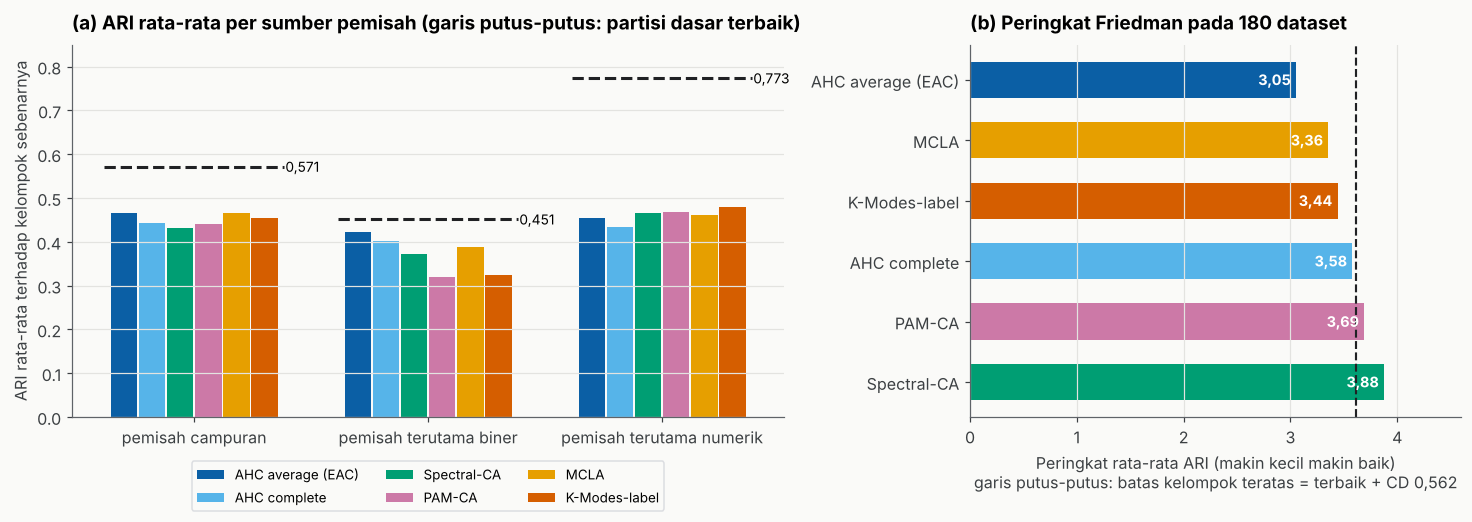

In [20]:
# Visualisasi 6 · Simulasi semi-sintetis: ARI enam fungsi konsensus dan partisi dasar terbaik (180 dataset)
sumber = list(SIM_VB["Sumber pemisah"].unique())
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.9), gridspec_kw={"width_ratios": [1.45, 1]})
ax = axs[0]; w = 0.12; x = np.arange(len(sumber))
for i, c in enumerate(CONS6):
    v = [SIM_VB[(SIM_VB["Sumber pemisah"] == s) & (SIM_VB.Metode == c)]["ARI rata-rata konsensus"].iloc[0] for s in sumber]
    ax.bar(x + (i - 2.5) * w, v, w * 0.95, color=WARNA_FUNGSI[c], label=LABEL_FUNGSI[c])
bb = [SIM_VB[SIM_VB["Sumber pemisah"] == s]["ARI rata-rata base terbaik per dataset"].iloc[0] for s in sumber]
for xi, b in zip(x, bb):
    ax.hlines(b, xi - 3.2 * w, xi + 3.2 * w, color="#202124", lw=2, ls="--"); ax.text(xi + 3.25 * w, b, koma(b, 3), va="center", fontsize=9)
ax.set_xticks(x, [f"pemisah {s}" for s in sumber]); ax.set_ylabel("ARI rata-rata terhadap kelompok sebenarnya"); ax.grid(axis="x", visible=False)
ax.set_title("(a) ARI rata-rata per sumber pemisah (garis putus-putus: partisi dasar terbaik)")
ax.set_ylim(0, 0.85); ax.legend(ncol=3, fontsize=8.8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax = axs[1]; f0 = SIM_FR[(SIM_FR["Kelompok dataset"] == "Semua dataset") & (SIM_FR.Kriteria == "ARI")].iloc[0]
pk = pd.Series({c: f0[f"peringkat {SINGKAT[c]}"] for c in CONS6}).sort_values()
cd = f0["CD Nemenyi (α = 0,05)"]; yy = np.arange(len(pk))
ax.barh(yy, pk.values, color=[WARNA_FUNGSI[c] for c in pk.index], height=0.6)
ax.axvline(pk.iloc[0] + cd, color="#202124", ls="--", lw=1.4)
for i, v in enumerate(pk.values): ax.text(v - 0.05, i, koma(v, 2), ha="right", va="center", color="white", fontsize=9.5, fontweight="bold")
ax.set_yticks(yy, [LABEL_FUNGSI[c] for c in pk.index]); ax.invert_yaxis(); ax.set_xlim(0, 4.6)
ax.set_xlabel(f"Peringkat rata-rata ARI (makin kecil makin baik)\ngaris putus-putus: batas kelompok teratas = terbaik + CD {koma(cd, 3)}"); ax.set_title("(b) Peringkat Friedman pada 180 dataset"); ax.grid(axis="y", visible=False)
fig.tight_layout(); simpan(fig, "V6_simulasi_semi_sintetis.png"); plt.show()


# BAGIAN 10B · Ekspor 180 dataset semi-sintetis
| | |
|---|---|
| **Tujuan** | Menyimpan ke-180 dataset yang dipakai di Bagian 10 agar bisa diperiksa atau dipakai ulang tanpa menjalankan generator (misalnya bila reviewer memintanya). |
| **Cara** | Tiap dataset dibangkitkan ulang dengan fungsi `bangkitkan` dan seed yang sama persis dengan Bagian 10, lalu disimpan dalam skala asli (sebelum log1p dan Min-Max) beserta kolom `KELOMPOK_BENAR`. |
| **Keluaran** | `hasil_konsensus/Dataset_Semi_Sintetis_180.zip` berisi `data/SIMxxx_….csv` (180 file, masing-masing 1.368 baris × 9 variabel), `daftar_dataset.csv` (sumber pemisah, tingkat pemisahan, K benar, replikasi, seed, a_num, a_bin, ukuran kelompok) dan `README.txt`. Daftar dataset juga masuk ke workbook (sheet 22). |
| **Uji ulang** | Enam dataset (satu per sumber pemisah × K) dibaca kembali dari ZIP, diproses dengan pipeline yang sama, lalu ARI keenam fungsi dibandingkan dengan hasil Bagian 10; harus identik. |

In [21]:
import zipfile, io
EN_SUMBER = {"campuran": "mixed", "biner": "mainly_binary", "numerik": "mainly_numeric"}
EN_LEVEL = {"rendah": "low", "sedang": "medium", "tinggi": "high"}
ZIP_SIM = os.path.join(OUT_DIR, "Dataset_Semi_Sintetis_180.zip")

def dataset_sim(i, dom, lev, K, r):
    a_num, a_bin = LEVEL[dom][lev]; seed = seed_sim(dom, lev, K, r)
    d, y = bangkitkan(PARAM, K, a_num, a_bin, dom, seed=seed); d = d.copy()
    for c in NUMERIK:
        if np.allclose(d[c], np.round(d[c])): d[c] = np.round(d[c]).astype(np.int64)
    for c in BINER: d[c] = d[c].astype(int)
    d.insert(0, "ID_OBJEK", np.arange(1, len(d) + 1)); d["KELOMPOK_BENAR"] = y + 1
    nama = f"SIM{i:03d}_{EN_SUMBER[dom]}_{EN_LEVEL[lev]}_K{K}_r{r + 1:02d}.csv"
    info = {"No": i, "File": "data/" + nama, "Sumber pemisah": LABEL_SUMBER[dom], "Pemisahan": lev, "K benar": K, "Replikasi": r + 1,
            "seed data": seed, "a_num": a_num, "a_bin": a_bin, "n": len(d), "Ukuran kelompok (1..K)": "/".join(map(str, np.bincount(y)))}
    return nama, d, info

README_SIM = "\n".join([
    "Semi-synthetic datasets for: Comparing Unweighted Consensus Functions for Clustering Mixed-Type MSME Data in East Java",
    "=" * 118, "",
    "180 datasets = 3 separation sources (mixed, mainly_binary, mainly_numeric) x 3 separation levels (low, medium, high)",
    "x true K (3, 4) x 10 replicates. Each file has n = 1,368 objects, the same size as the real registry.", "",
    "Columns",
    "  ID_OBJEK        object index 1..1368",
    "  " + ", ".join(NUMERIK),
    "                  numeric variables on their original scale (every value is a quantile of the real variable);",
    "                  the analysis applies log1p to " + ", ".join(LOG1P) + ", then Min-Max to all six",
    "  " + ", ".join(BINER),
    "                  binary variables, 1 = YA (yes), 0 = TIDAK (no); marginal proportions follow the real data",
    "  KELOMPOK_BENAR  generating (true) group, 1..K; group 1 is the largest.",
    "                  Used only to score the clusterings (ARI, NMI); never given to any algorithm.", "",
    "Generator (Gaussian copula)",
    "  latent L = a * Z[group] + E, with a = a_num for the six numeric variables and a = a_bin for the three binary ones;",
    "  Z = random group centres, E = standard normal noise carrying the real OMSET-BIAYA_PRODUKSI correlation",
    f"  (rho = {PARAM['rho_ob']:.4f} on the log scale). Each latent column is standardised, then mapped to the empirical",
    "  quantiles of the real variable (numeric) or thresholded at the real proportion (binary).",
    "  Group proportions: K = 3 -> 66/20/14 %, K = 4 -> 60/20/13/7 %.",
    "  Separation settings (a_num, a_bin):",
    *[f"    {EN_SUMBER[d]:<15}" + "  ".join(f"{EN_LEVEL[lv]} ({a[0]:.1f}, {a[1]:.1f})" for lv, a in lv_.items()) for d, lv_ in LEVEL.items()],
    "  seed = 10000*(index of source in [mainly_binary, mainly_numeric, mixed] + 1) + 1000*level_index + 100*K + (replicate - 1)", "",
    "daftar_dataset.csv lists every file with its condition, seed, a_num, a_bin and group sizes.",
    "Notebook_Perbandingan_Fungsi_Konsensus_UMKM.ipynb (Sections 10 and 10B) regenerates every file exactly.", ""])

DAFTAR = []
tmp = ZIP_SIM + ".tmp"
with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as zf:
    for i, t in enumerate(TUGAS_SIM, 1):
        nama, d, info = dataset_sim(i, *t); zf.writestr("data/" + nama, d.to_csv(index=False)); DAFTAR.append(info)
    DAFTAR = pd.DataFrame(DAFTAR)
    en = DAFTAR.rename(columns={"No": "no", "File": "file", "Sumber pemisah": "separation_source", "Pemisahan": "separation_level", "K benar": "true_K",
                                "Replikasi": "replicate", "seed data": "seed", "Ukuran kelompok (1..K)": "group_sizes"})
    en["separation_source"] = en.separation_source.map({v: EN_SUMBER[k] for k, v in LABEL_SUMBER.items()}); en["separation_level"] = en.separation_level.map(EN_LEVEL)
    zf.writestr("daftar_dataset.csv", en.to_csv(index=False)); zf.writestr("README.txt", README_SIM)
os.replace(tmp, ZIP_SIM)
assert (DAFTAR["seed data"].values == SIM["seed data"].values).all(), "urutan dataset tidak sama dengan Bagian 10"
print(f"✔ {len(DAFTAR)} dataset tersimpan: {ZIP_SIM} ({os.path.getsize(ZIP_SIM) / 1e6:.1f} MB)")
display(DAFTAR.head(6))

✔ 180 dataset tersimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/Dataset_Semi_Sintetis_180.zip (2.3 MB)


,No,File,Sumber pemisah,Pemisahan,K benar,Replikasi,seed data,a_num,a_bin,n,Ukuran kelompok (1..K)
0,1,data/SIM001_mixed_low_K3_r01.csv,campuran,rendah,3,1,30300,1.0,1.0,1368,902/274/192
1,2,data/SIM002_mixed_low_K3_r02.csv,campuran,rendah,3,2,30301,1.0,1.0,1368,902/274/192
2,3,data/SIM003_mixed_low_K3_r03.csv,campuran,rendah,3,3,30302,1.0,1.0,1368,902/274/192
3,4,data/SIM004_mixed_low_K3_r04.csv,campuran,rendah,3,4,30303,1.0,1.0,1368,902/274/192
4,5,data/SIM005_mixed_low_K3_r05.csv,campuran,rendah,3,5,30304,1.0,1.0,1368,902/274/192
5,6,data/SIM006_mixed_low_K3_r06.csv,campuran,rendah,3,6,30305,1.0,1.0,1368,902/274/192


In [22]:
# Uji ulang: baca kembali dari ZIP → pipeline yang sama → ARI harus identik dengan Bagian 10
def _uji_ulang(file):
    with zipfile.ZipFile(ZIP_SIM) as zf: d = pd.read_csv(io.BytesIO(zf.read(file)))
    Xs = normalisasi(d[NUMERIK], d[BINER]); K = int(d.KELOMPOK_BENAR.max())
    Pp = base3(Xs, gower_of(Xs), K, RANDOM_STATE); out = konsensus6(Pp, B3, K, RANDOM_STATE)
    return {c: adjusted_rand_score(d.KELOMPOK_BENAR, out[c]) for c in CONS6}
pilih = DAFTAR.groupby(["Sumber pemisah", "K benar"], sort=False).head(1)
hasil = Parallel(n_jobs=N_JOBS)(delayed(_uji_ulang)(f) for f in pilih.File)
cek = []
for (_, r), h in zip(pilih.iterrows(), hasil):
    s = SIM[SIM["seed data"] == r["seed data"]].iloc[0]
    cek.append({"File": r.File, "selisih ARI maksimum": max(abs(h[c] - s[f"ARI {c}"]) for c in CONS6), **{f"ARI {SINGKAT[c]}": h[c] for c in CONS6}})
CEK_EKSPOR = pd.DataFrame(cek)
print("✔ dataset ekspor menghasilkan ARI identik dengan Bagian 10" if CEK_EKSPOR["selisih ARI maksimum"].max() < 1e-12 else "✘ ada selisih ARI, periksa versi pustaka")
display(CEK_EKSPOR.round(4))

✔ dataset ekspor menghasilkan ARI identik dengan Bagian 10


,File,selisih ARI maksimum,ARI AHC avg,ARI AHC comp,ARI Spectral C,ARI PAM 1−C,ARI MCLA,ARI K-Modes label
0,data/SIM001_mixed_low_K3_r01.csv,0.0,-0.1114,-0.1142,-0.1119,0.2001,-0.1113,0.1841
1,data/SIM011_mixed_low_K4_r01.csv,0.0,-0.0432,0.0246,-0.1295,0.0056,-0.0413,0.0119
2,data/SIM061_mainly_binary_low_K3_r01.csv,0.0,-0.0241,-0.0241,-0.0228,-0.0220,-0.0213,-0.0032
3,data/SIM071_mainly_binary_low_K4_r01.csv,0.0,0.0185,0.0185,0.0186,-0.0150,0.0184,-0.0146
4,data/SIM121_mainly_numeric_low_K3_r01.csv,0.0,0.0114,0.0114,0.0113,0.0104,0.0093,0.0114
5,data/SIM131_mainly_numeric_low_K4_r01.csv,0.0,0.2445,0.2190,0.2325,0.2311,0.2470,0.2311


# BAGIAN 10C · Visualisasi klaster akhir (EAC, K = 4)
Sebaran klaster pada proyeksi MDS dua dimensi dari jarak Gower, matriks co-association yang diurutkan menurut klaster, dan profil variabel tiap klaster. Persentase sumbu MDS dihitung terhadap total variansi konfigurasi jarak Gower (jumlah seluruh nilai eigen).

Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V7_sebaran_klaster_MDS.png


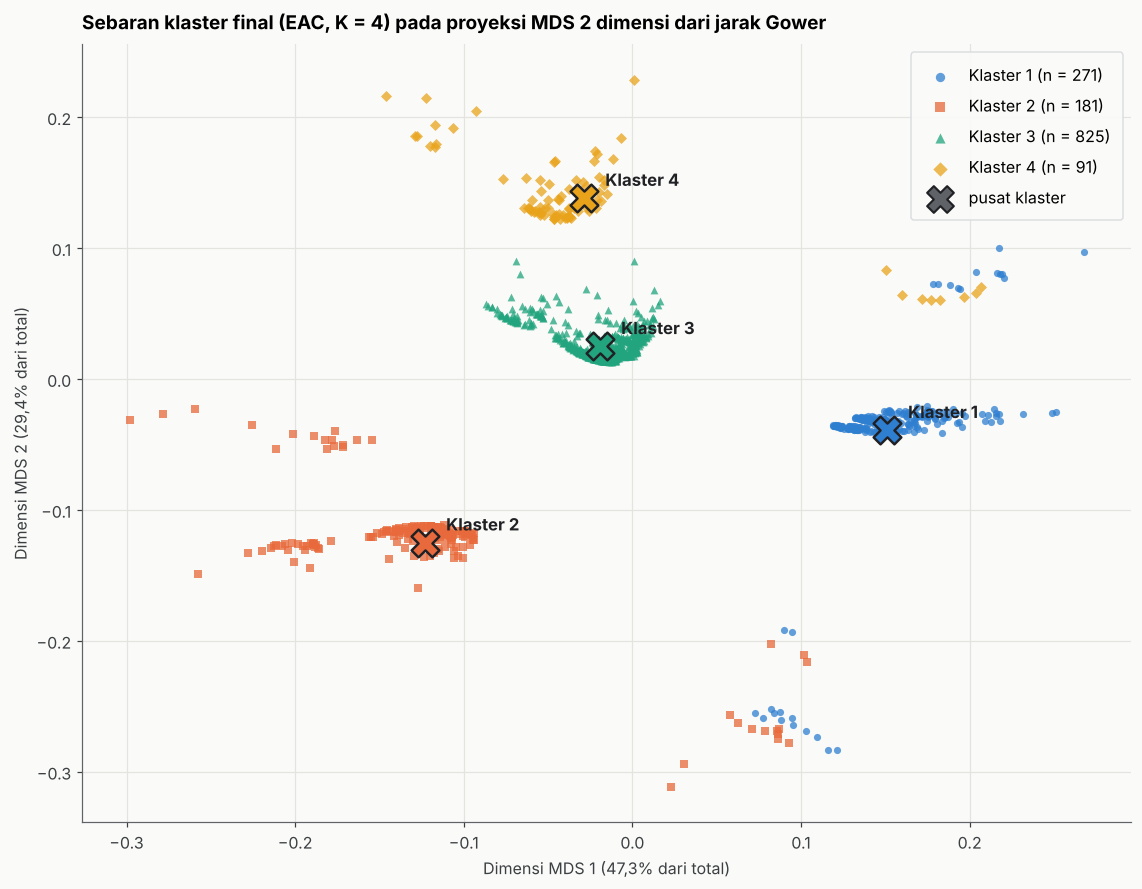

Dua dimensi pertama menjelaskan 76,7% dari total (47,3% dan 29,4%).


In [23]:
# Visualisasi 7 · Sebaran klaster final (EAC, K = 4) pada proyeksi MDS 2 dimensi dari jarak Gower
LAB4 = MAIN[4]["out"]["AHC average"]
ukuran = np.bincount(LAB4)
xy, ev = EMB[:, :2].copy(), np.sort(EIG)[::-1][:2]
if xy[LAB4 == 0, 0].mean() < 0: xy[:, 0] *= -1      # orientasi sumbu MDS bersifat bebas tanda; disamakan dengan gambar laporan
if xy[LAB4 == 3, 1].mean() < 0: xy[:, 1] *= -1
pct = ev / EIG.sum() * 100
fig, ax = plt.subplots(figsize=(10.5, 8.2))
for k in range(4):
    m = LAB4 == k
    ax.scatter(xy[m, 0], xy[m, 1], s=26 if MARKER_KLASTER[k] != "o" else 22, marker=MARKER_KLASTER[k], color=WARNA_KLASTER[k],
               alpha=0.75, lw=0, label=f"Klaster {k + 1} (n = {ukuran[k]})", zorder=2)
for k in range(4):
    cx, cy = xy[LAB4 == k].mean(0)
    ax.scatter(cx, cy, marker="X", s=330, color=WARNA_KLASTER[k], edgecolor="#202124", lw=1.6, zorder=4)
    ax.annotate(f"Klaster {k + 1}", (cx, cy), xytext=(14, 8), textcoords="offset points", fontsize=11, fontweight="bold", color="#202124", zorder=5)
ax.scatter([], [], marker="X", s=180, color="#5F6368", edgecolor="#202124", lw=1.4, label="pusat klaster")
ax.legend(loc="upper right", fontsize=10.5, markerscale=1.3, borderpad=0.8, labelspacing=0.7)
ax.set_xlabel(f"Dimensi MDS 1 ({koma(pct[0], 1)}% dari total)"); ax.set_ylabel(f"Dimensi MDS 2 ({koma(pct[1], 1)}% dari total)")
ax.set_title("Sebaran klaster final (EAC, K = 4) pada proyeksi MDS 2 dimensi dari jarak Gower", fontsize=12.5)
fig.tight_layout(); simpan(fig, "V7_sebaran_klaster_MDS.png"); plt.show()
print(f"Dua dimensi pertama menjelaskan {koma(pct.sum(), 1)}% dari total ({koma(pct[0], 1)}% dan {koma(pct[1], 1)}%).")


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V8_coassociation_K4.png


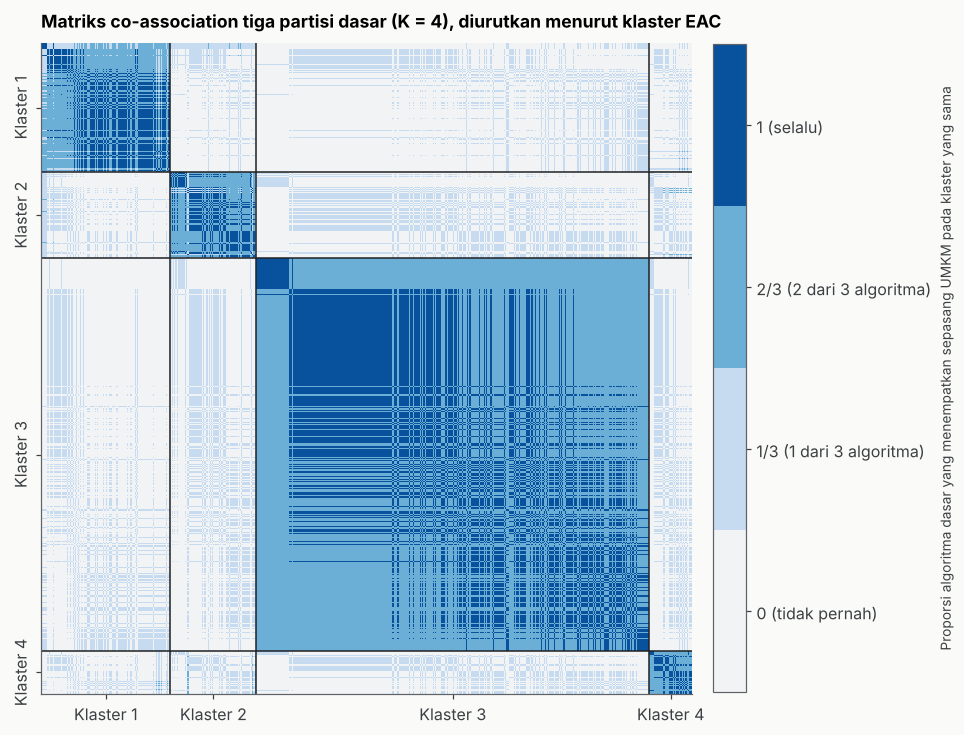

In [24]:
# Visualisasi 8 · Matriks co-association (K = 4) diurutkan menurut klaster EAC
urut = np.lexsort((EMB[:, 0], LAB4)); Cs = Cm4[np.ix_(urut, urut)]
batas = np.cumsum(np.bincount(LAB4))[:-1]; tengah = np.cumsum(np.bincount(LAB4)) - np.bincount(LAB4) / 2
cmap = mpl.colors.ListedColormap(["#F1F3F4", "#C6DBEF", "#6BAED6", "#08519C"])
fig, ax = plt.subplots(figsize=(8.6, 7.6))
im = ax.imshow(Cs, cmap=cmap, vmin=-1 / 6, vmax=1 + 1 / 6, interpolation="nearest")
for b in batas: ax.axhline(b - 0.5, color="#202124", lw=1); ax.axvline(b - 0.5, color="#202124", lw=1)
ax.set_xticks(tengah, [f"Klaster {k + 1}" for k in range(4)]); ax.set_yticks(tengah, [f"Klaster {k + 1}" for k in range(4)], rotation=90, va="center")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, ticks=[0, 1 / 3, 2 / 3, 1], fraction=0.046, pad=0.03)
cb.ax.set_yticklabels(["0 (tidak pernah)", "1/3 (1 dari 3 algoritma)", "2/3 (2 dari 3 algoritma)", "1 (selalu)"])
cb.set_label("Proporsi algoritma dasar yang menempatkan sepasang UMKM pada klaster yang sama", fontsize=9)
ax.set_title("Matriks co-association tiga partisi dasar (K = 4), diurutkan menurut klaster EAC", fontsize=11.5)
fig.tight_layout(); simpan(fig, "V8_coassociation_K4.png"); plt.show()


Gambar disimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/V9_profil_klaster.png


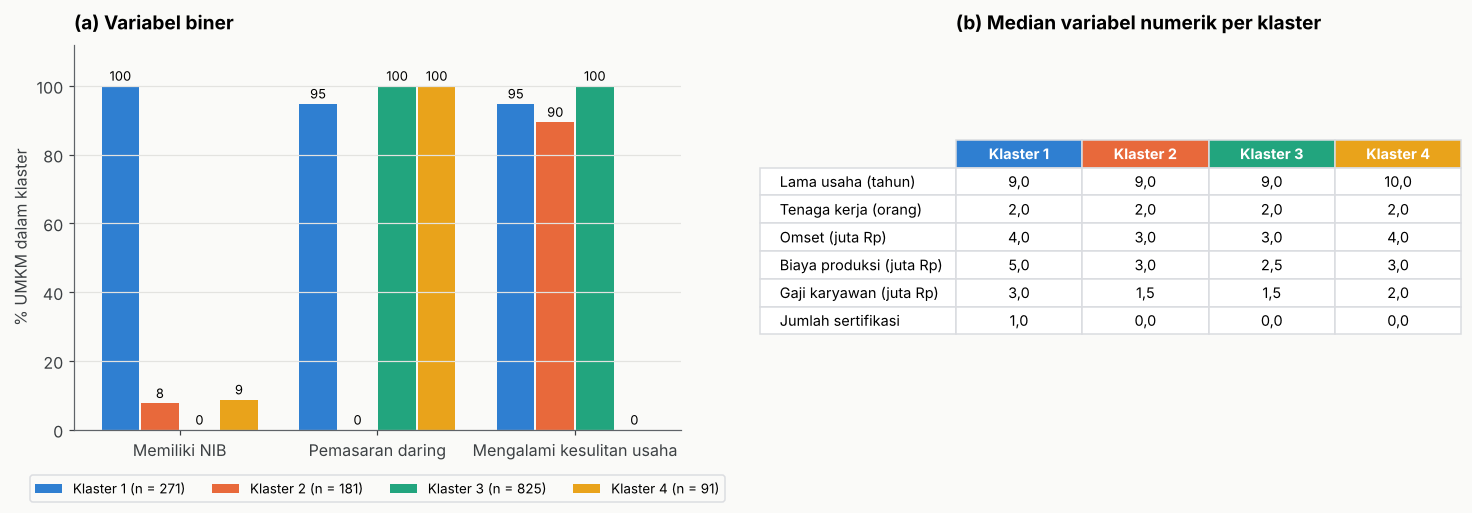

,Memiliki NIB,Pemasaran daring,Mengalami kesulitan usaha
Klaster,,,
1,100.0,94.8,94.8
2,7.7,0.0,89.5
3,0.0,100.0,100.0
4,8.8,100.0,0.0


In [25]:
# Visualisasi 9 · Profil klaster: variabel biner (% ya) dan median variabel numerik
PR = bersih.assign(Klaster=LAB4 + 1)
biner = {"NIB_STATUS_BIN": "Memiliki NIB", "PEMASARAN_ONLINE_BIN": "Pemasaran daring", "KESULITAN_USAHA_BIN": "Mengalami kesulitan usaha"}
pb = PR.groupby("Klaster")[list(biner)].mean().mul(100).rename(columns=biner)
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axs[0]; x = np.arange(len(biner)); w = 0.2
for k in range(4):
    v = pb.loc[k + 1].values
    bars = ax.bar(x + (k - 1.5) * w, v, w * 0.95, color=WARNA_KLASTER[k], label=f"Klaster {k + 1} (n = {ukuran[k]})")
    for b, val in zip(bars, v): ax.text(b.get_x() + b.get_width() / 2, val + 1.5, f"{val:.0f}", ha="center", fontsize=8.5)
ax.set_xticks(x, list(biner.values())); ax.set_ylim(0, 112); ax.set_ylabel("% UMKM dalam klaster"); ax.grid(axis="x", visible=False)
ax.set_title("(a) Variabel biner"); ax.legend(fontsize=8.8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
num = {"LAMA_USAHA": "Lama usaha (tahun)", "JUMLAH_TENAGA_KERJA": "Tenaga kerja (orang)", "OMSET": "Omset (juta Rp)",
       "BIAYA_PRODUKSI": "Biaya produksi (juta Rp)", "GAJI_KARYAWAN": "Gaji karyawan (juta Rp)", "SERTIFIKASI_JUMLAH": "Jumlah sertifikasi"}
med = PR.groupby("Klaster")[list(num)].median()
for c in ["OMSET", "BIAYA_PRODUKSI", "GAJI_KARYAWAN"]: med[c] = med[c] / 1e6
med = med.rename(columns=num).T
ax = axs[1]; ax.axis("off")
tb = ax.table(cellText=[[f"{v:,.1f}".replace(",", "X").replace(".", ",").replace("X", ".") for v in r] for r in med.values],
              rowLabels=med.index, colLabels=[f"Klaster {k}" for k in med.columns], loc="center", cellLoc="center")
tb.auto_set_font_size(False); tb.set_fontsize(9.5); tb.scale(1, 1.6)
for (r, c), cell in tb.get_celld().items():
    cell.set_edgecolor("#DADCE0")
    if r == 0 and c >= 0: cell.set_facecolor(WARNA_KLASTER[c]); cell.get_text().set_color("white"); cell.get_text().set_fontweight("bold")
ax.set_title("(b) Median variabel numerik per klaster")
fig.tight_layout(); simpan(fig, "V9_profil_klaster.png"); plt.show()
display(pb.round(1))


# BAGIAN 11 · Workbook Excel hasil

In [26]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
def simpan_excel(path, sheets, lebar_ringkasan=None):
    tmp = path[:-5] + ".tmp.xlsx"
    with pd.ExcelWriter(tmp, engine="openpyxl") as xw:
        for nama, dd in sheets.items(): dd.to_excel(xw, sheet_name=nama[:31], index=False)
        for ws in xw.book.worksheets:
            for c in ws[1]: c.font = Font(bold=True, color="FFFFFF"); c.fill = PatternFill("solid", fgColor="1F3864"); c.alignment = Alignment(wrap_text=True, vertical="center")
            ws.freeze_panes = "A2"
            for j, col in enumerate(ws.columns, 1):
                head = str(col[0].value); w = max((len(str(c.value)) for c in list(col)[:300] if c.value is not None), default=8)
                ws.column_dimensions[get_column_letter(j)].width = min(max(10, w + 2), 48)
                fmt = "0.00" if ("CHI" in head or "%" in head or "χ²" in head) else ("0.00E+00" if head == "p-value" else "0.0000")
                for c in list(col)[1:]:
                    if isinstance(c.value, float): c.number_format = fmt
            if ws.title.startswith("00"):
                ws.column_dimensions["A"].width = 55; ws.column_dimensions["B"].width = 140
                for r in ws.iter_rows(min_row=2):
                    for c in r: c.alignment = Alignment(wrap_text=True, vertical="top")
                    if r[0].value and not r[1].value: r[0].font = Font(bold=True)
    os.replace(tmp, path); print("✔ tersimpan:", path)

J = lambda f: " | ".join(f"{SINGKAT[c]} {f(c):.4f}" for c in CONS6)
ev = lambda K, c, k: EV[(EV.K == K) & (EV.Metode == c)][k].iloc[0]
l1 = lambda K, c: L1T[(L1T.K == K) & (L1T.Metode == c)]["ARI rata-rata (stabilitas)"].iloc[0]
l3 = lambda K, j, c: L3T[(L3T.K == K) & (L3T["Gangguan data"] == j) & (L3T.Metode == c)]["ARI rata-rata vs data penuh"].iloc[0]
tal = lambda cak: " | ".join(f"{SINGKAT[c]} {int(TAL[(TAL['Cakupan uji']==cak)&(TAL.Metode==c)]['masuk kelompok teratas'].iloc[0])}/{int(TAL[(TAL['Cakupan uji']==cak)&(TAL.Metode==c)]['uji signifikan'].iloc[0])}" for c in CONS6)
sfr = lambda kel: SIM_FR[(SIM_FR["Kelompok dataset"] == kel) & (SIM_FR.Kriteria == "ARI")].iloc[0]
urut_sim = lambda kel: " > ".join(f"{SINGKAT[c]} ({sfr(kel)[f'peringkat {SINGKAT[c]}']:.2f})" for c in sorted(CONS6, key=lambda c: sfr(kel)[f"peringkat {SINGKAT[c]}"]))
RING = pd.DataFrame([
    ("RANCANGAN", ""),
    ("Data", f"{len(X):,} UMKM × 9 variabel (6 numerik + 3 biner); log1p (omset, biaya produksi, gaji) + Min-Max"),
    ("Ensemble", "3 base: K-Means, K-Prototypes, K-Medoids (Gower); seed 42"),
    ("6 fungsi konsensus (tanpa bobot)", " | ".join(CONS6)),
    ("Kriteria", "SC (Gower) | DBI, CHI (MDS 10 dimensi) | ANMI | SC Euclid (uji kepekaan) | ukuran klaster | ARI (ketahanan, simulasi)"),
    ("Protokol K", "K tetap = 3 dan 4; K = 2–10 dilaporkan sebagai pelengkap"),
    ("", ""), ("DATA ASLI", ""),
    ("K = 4: SC Gower", J(lambda c: ev(4, c, "SC"))),
    ("K = 4: ANMI", J(lambda c: ev(4, c, "ANMI"))),
    ("K = 3: SC Gower", J(lambda c: ev(3, c, "SC"))),
    ("K optimal per fungsi (komposit lintas K)", " | ".join(f"{SINGKAT[c]} {k}" for c, k in KOPT.items())),
    ("Spearman ρ SC Gower vs SC Euclid (K = 3–10)", " | ".join(f"K={int(r.K)}: {r['Spearman ρ (SC Gower vs SC Euclid, 6 fungsi)']:.2f}" for _, r in SP.iterrows() if not pd.isna(r["Spearman ρ (SC Gower vs SC Euclid, 6 fungsi)"]))),
    ("", ""), ("KETAHANAN", ""),
    ("Lapis 1 stabilitas 30 seed, K = 4", J(lambda c: l1(4, c))),
    ("Lapis 3 subsampel 80%, K = 4 (ARI vs data penuh)", J(lambda c: l3(4, "Subsampel 80%", c))),
    ("Lapis 3 derau biner 5%, K = 4 (ARI vs data penuh)", J(lambda c: l3(4, "Derau biner 5%", c))),
    ("Masuk kelompok teratas Friedman–Nemenyi (uji utama)", tal("utama")),
    ("Masuk kelompok teratas Friedman–Nemenyi (uji tekanan)", tal("uji tekanan")),
    ("", ""), ("SIMULASI SEMI-SINTETIS (ARI terhadap kelompok yang diketahui)", ""),
    ("Peringkat rata-rata, 180 dataset", urut_sim("Semua dataset") + f" | p = {sfr('Semua dataset')['p-value']:.3g}; CD = {sfr('Semua dataset')['CD Nemenyi (α = 0,05)']:.3f}"),
    *[(f"Peringkat rata-rata, pemisah {d} (60)", urut_sim(d) + f" | p = {sfr(d)['p-value']:.3g}; CD = {sfr(d)['CD Nemenyi (α = 0,05)']:.3f}") for d in LABEL_SUMBER.values()],
    ("Kelompok teratas (180 dataset)", sfr("Semua dataset")["Kelompok teratas (tidak berbeda nyata dari terbaik)"]),
    *[(f"Kelompok teratas (pemisah {d})", sfr(d)["Kelompok teratas (tidak berbeda nyata dari terbaik)"]) for d in LABEL_SUMBER.values()],
    ("Konsensus vs base terbaik", " | ".join(f"{r['Sumber pemisah']}: ARI base terbaik {r['ARI rata-rata base terbaik per dataset']:.3f}, AHC avg {r['ARI rata-rata konsensus']:.3f}" for _, r in SIM_VB[SIM_VB.Metode == "AHC average"].iterrows())),
], columns=["Item", "Nilai"])
DESAIN_SIM = pd.DataFrame([{"Sumber pemisah": LABEL_SUMBER[d], "Pemisahan": lv, "a_num": a[0], "a_bin": a[1]} for d, lv_ in LEVEL.items() for lv, a in lv_.items()])
lab = pd.DataFrame({"ID_BINAAN": bersih.ID_BINAAN.values})
for K in K_UJI:
    for c in CONS6: lab[f"K{K} {c}"] = MAIN[K]["out"][c]
SHEETS = {"00 Ringkasan": RING, "01 Data bersih (1368)": bersih, "02 Missing value": cek_missing.reset_index().rename(columns={"index": "Variabel"}),
          "03 Log imputasi": log_imputasi, "04 Siap clustering": X.reset_index().rename(columns={"index": "ID_BINAAN"}),
          "05 Eval utama semua K": EV, "06 Peringkat per K": RK, "07 Protokol K": PROTOKOL, "08 SC Gower vs Euclid": SP,
          "10 Lapis1 stabilitas seed": L1T, "11 Lapis2 eval perturbasi": L2E, "12 Lapis2 stabilitas": L2S, "13 Lapis3 data": L3T,
          "14 Friedman per kriteria": FRR, "15 Rekap kelompok teratas": TAL, "16 Nilai per replikasi": BLK,
          "17 Sim desain": DESAIN_SIM, "18 Sim hasil per dataset": SIM, "19 Sim ringkasan kondisi": SIM_KOND, "20 Sim Friedman": SIM_FR,
          "21 Sim konsensus vs base": SIM_VB, "22 Label K3 K4": lab, "23 Sim daftar dataset": DAFTAR}
SHEETS = {f"{i:02d} {k[3:]}": v for i, (k, v) in enumerate(SHEETS.items())}   # nomor sheet berurutan
simpan_excel(os.path.join(OUT_DIR, "Hasil_Perbandingan_Fungsi_Konsensus_UMKM.xlsx"), SHEETS)
display(RING)

✔ tersimpan: UMKM_Fungsi_Konsensus/hasil_konsensus/Hasil_Perbandingan_Fungsi_Konsensus_UMKM.xlsx


,Item,Nilai
0,RANCANGAN,
1,Data,"1,368 UMKM × 9 variabel (6 numerik + 3 biner);..."
2,Ensemble,"3 base: K-Means, K-Prototypes, K-Medoids (Gowe..."
3,6 fungsi konsensus (tanpa bobot),AHC average | AHC complete | Spectral (C) | K-...
4,Kriteria,"SC (Gower) | DBI, CHI (MDS 10 dimensi) | ANMI ..."
5,Protokol K,K tetap = 3 dan 4; K = 2–10 dilaporkan sebagai...
6,,
7,DATA ASLI,
8,K = 4: SC Gower,AHC avg 0.5612 | AHC comp 0.5612 | Spectral C ...
9,K = 4: ANMI,AHC avg 0.6705 | AHC comp 0.6705 | Spectral C ...
